# **NAME: KEORAPETSE MADUE**

# **STUDENT NUMBER: ST10485113**

# **MODULE: RPDA8412 - RESEARCH PROJECT**



<BR>

# **Research Title: An integrated framework for enhancing customer retention strategies through customer segmentation, churn prediction and explainable artificial intelligence in the South African telecommunications sector**

# **Import libraries**

In [ ]:
#install libraries
!pip install xgboost shap

In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys

#library train/test split
from sklearn.model_selection import train_test_split

#import k means clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# import Machine learning models for churn prediction
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

#import evaluation metrics for churn prediction models
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score, RocCurveDisplay

#import shap for XAI
import shap


In [ ]:
import matplotlib
import sklearn

#Display library versions
print(f'Python version: {sys.version}')
print(f'Pandas version: {pd.__version__}')
print(f'Numpy version: {np.__version__}')
print(f'Seaborn version: {sns.__version__}')
print(f'XGBoost version: {xgb.__version__}')
print(f'Shap version: {shap.__version__}')
print(f'Matplotlib version: {matplotlib.__version__}')
print(f'Scikit-learn version: {sklearn.__version__}')

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Pandas version: 2.2.3
Numpy version: 2.1.3
Seaborn version: 0.13.2
XGBoost version: 3.4.1
Shap version: 0.54.1
Matplotlib version: 3.10.0
Scikit-learn version: 1.6.1


In [ ]:
#set seed to ensure reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# **Download dataset and load into pandas DataFrame**

In [ ]:
#load dataset into pandas dataframe
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [ ]:
#verify data has been loaded by displaying first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# **Exploratory Data Analysis (EDA)**

**EDA (Overview of dataset)**

In [ ]:
#shape of dataset
print(df.shape)
print('\n')
print(f'Number of rows: {df.shape[0]}')
print(f'Number of columns: {df.shape[1]}')

(7043, 21)


Number of rows: 7043
Number of columns: 21


In [ ]:
#Data structure - display column names and their datatypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Dataset is made up 7043 rows and 21 columns. Of the 21 columns, three columns are numerical (SeniorCitizen, tenure, and MonthlyCharges) while the remaining 18 columns are text/categorical. Appears that dataset does not have null values sinc all columns have 7043 records (null values to be confirmed in the coming stages)

In [ ]:
#check for missing values per column
print(df.isnull().sum())

print('\n')
#check for hidden blanks/empty values in text/categorical columns
text_columns = df.select_dtypes(include='object').columns
for column in text_columns:
  blank_values_count = (df[column].str.strip()=="").sum()
  if blank_values_count >0:
    print(f'Number of blank values in {column}: {blank_values_count}')


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Number of blank values in TotalCharges: 11


Check for missing values across all columns was performed, with no standard missing values (NaN or None) being found. A further check was performed to check for hidden blanks/empty values in the text columns, with 11 blank values found in the TotalCharges column.  

In [ ]:
#display rows of 11 customers who had blank totalcharges
df[df['TotalCharges'].str.strip()==""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


Key finding regarding the 11 customers who had blank TotalCharges is that they all had a tenure of 0, hence no TotalCharges have yet been charged to customers.Check customers with tenure = 0, if eleven cusomters, We will set the totalcharges to be zero.

In [ ]:
#display customers who have tenure = 0
print(f'Number of customers with tenure = 0: {df[df["tenure"]==0].shape[0]}')

print('\n')

#display monthly charges, total charges and churn of customers who have tenure = 0
print(df.loc[df['tenure'] == 0, ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

Number of customers with tenure = 0: 11


      tenure  MonthlyCharges TotalCharges Churn
488        0           52.55                 No
753        0           20.25                 No
936        0           80.85                 No
1082       0           25.75                 No
1340       0           56.05                 No
3331       0           19.85                 No
3826       0           25.35                 No
4380       0           20.00                 No
5218       0           19.70                 No
6670       0           73.35                 No
6754       0           61.90                 No


Above code provides confirmation that only 11 cusotmers had a tenure of 0, with all 11 cusotmers having Churn = No, which is expected since customers who recently joined have not yet had no opportunity to leave yet.

In [ ]:
#fill the 11 records which have blank values in TotalCharges with 0
#create a copy of the dataframe before filling blanks with zeros
df_clean = df.copy()

#convert TotalCharges column datatype from text to numbers
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
print(f'TotalCharges data type: {df_clean["TotalCharges"].dtype}')

#missing values after conversion
print(f'Missing values after converting TotalCharges to numeric datatype: {df_clean["TotalCharges"].isnull().sum()}')

#fill blank values in TotalCharges with 0
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

#verify that blank values have been filled
print(f'Missing values after filling blank values in TotalCharges: {df_clean["TotalCharges"].isnull().sum()}')


TotalCharges data type: float64
Missing values after converting TotalCharges to numeric datatype: 11
Missing values after filling blank values in TotalCharges: 0


A copy of the orginal dataframe is created (df_clean) after which we converted the TotalCharges column from text to numeric. Because these customers are new customers who just recently joined the company (tenure = 0), their TotalCharges was set to zero as charges are yet to be accrued.

In [ ]:
#check for duplicate rows
print(f'Count of duplicated rows: {df_clean.duplicated().sum()}')

#check for duplicated customers
print(f'Count of duplicated customers: {df_clean["customerID"].duplicated().sum()}')

Count of duplicated rows: 0
Count of duplicated customers: 0


In [ ]:
#check distribution in target variable
print('Count of each class:')
print(df_clean['Churn'].value_counts())

print('\n')

#proportion of each class
print('Proportion of each class:')
print(df_clean['Churn'].value_counts(normalize=True).round(2))

Count of each class:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


Proportion of each class:
Churn
No     0.73
Yes    0.27
Name: proportion, dtype: float64


Of the 7043 customer records, 5174 (73%) did not churn while 1869 (27%) churned. From this distribution we see a moderate class imbalance in the target variable, with the majority (73%) of customers not churning compared to the 27% who did churn. Class imbalance needs to be accounted for when building models as class imbalance could lead to model performing well in terms the dominant class but poorly on the minority class.

In [ ]:
#display unique values found in text/categorical columns (except customerID)
for column in text_columns:
    if column != 'customerID':
        print(f"{column}: {df_clean[column].unique()}")

gender: ['Female' 'Male']
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
TotalCharges: [  29.85 1889.5   108.15 ...  346.45  306.6  6844.5 ]
Churn: ['No' 'Yes']


# **Exploratory Data Analysis (EDA)**

In [ ]:
#variable storing numerical columns (exluding SeniorCitizen as it is stored as 0/1 which represent Yes/No)
numeric_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']

#descriptive statistics - numerical columns
df_clean[numeric_columns].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80


All three columns have a count of 7043 rows, confirming that there are no missing values in the three columns. Tenure (i.e. customer tenure) ranges from 0 to 72 months (six years), with the average tenure of customers being about 32 months. Tenure has a mean (32.37) that is slightly higer then the median (29) thus suggesting a mild right skew. MonthlyCharges range from 18.25 to 118.75 with the average monthly charges being about 64.76. MonthlyCharges has a mean (64.76)  slightly lower than the median (70.35) thus suggesting a mild left skew, with low paying customers pullling the average monthly charges down.Total charges range from 0 to 8684.80, with the average total charges being about 2279.73. TotalCharges has a mean (2279.73) strongly above the median (1394.55), thus sugeesting a strong right skew distribution.

In [ ]:
#descriptive statistics of numeric columns against target variable
churn_group = df_clean.groupby('Churn')[numeric_columns].agg(['mean', 'median', 'std', 'min', 'max']).round(2).T
churn_group


Churn                       No      Yes
tenure         mean      37.57    17.98
               median    38.00    10.00
               std       24.11    19.53
               min        0.00     1.00
               max       72.00    72.00
MonthlyCharges mean      61.27    74.44
               median    64.43    79.65
               std       31.09    24.67
               min       18.25    18.85
               max      118.75   118.35
TotalCharges   mean    2549.91  1531.80
               median  1679.52   703.55
               std     2329.95  1890.82
               min        0.00    18.85
               max     8672.45  8684.80

Using the median as a way to represent the typical customers, customers who typically churned had been with the company for 10 months compared with 38 months for the typical customers who did not churn, suggesting that customers who churned are concentrated among the newwer customers. In terms of monthly charges, customers who typically churned paid higher monthly charges than those customers who did not churn , with the median monthly charges for churners being 79.65 compared to 64.43 for non-churners. The smaller standard deviation for churned customers (24.67) suggests that their monthly charges is less spread out, with their monthly charges more concentrated towards the higher end. Total charges for typical churned customers is lower (703.55) compared to those customers who did not churn (1679.52)

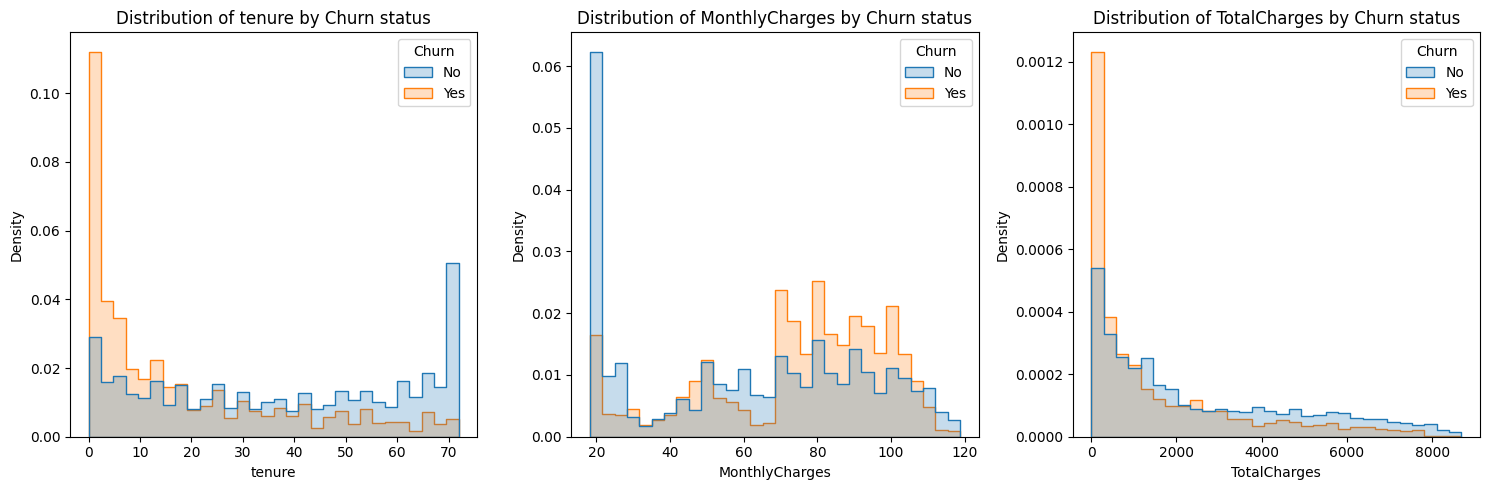

In [ ]:
#histograms plots of numerical columns by target variable
fig, axes = plt.subplots(1,3, figsize=(15,5))

for ax,column in zip(axes, numeric_columns):
  sns.histplot(data=df_clean, x=column, hue='Churn', ax=ax, bins=30, stat='density', common_norm=False, element='step')
  ax.set_title(f'Distribution of {column} by Churn status')

plt.tight_layout()
plt.show()


The tenure plot displays a high spike for churned customers (orange) at lower tenure periods, suggesting that newer customers at higher risk of churning, while non-churning customers show greater concentration at longer tenures, highlighting long term customer loyalty. In terms of monthly charges, we see a tall bar (around 20 units ) for monthly charges, with a large group of these customers on low monthly charges rarely churning while churned customers are more concentrated at higher monthly charges compared to non-churners, thus suggesting that the high monthly charges may be contributing to customers churning. Total charges plot shows similar distribution patterns to the tenure plot, whereby churned customers are concentrated at lower total charges while non-churners tend to spend more in total charges (which can be attributed to non-churners staying longer with the company, with total charges based on tenure and monthly charges)

In [ ]:
#check if customers with no internet services have monthly charges around 20
df_clean.groupby('InternetService')['MonthlyCharges'].median()

,MonthlyCharges
InternetService,
DSL,56.150
Fiber optic,91.675
No,20.150


From our Histogram, we saw a tall bar (around 20 units ) for monthly charges, with a large group of these customers on low monthly charges rarely churning. A possible hypothesis could be that these customers are paying for basic phone services and might not be subscribed to additional internet services. A check was done to confirm the hypothesis by getting the median monthly charges of the various categories of the attribute “Internet Service”. From the check, we see that the category of customers who did not have Internet Service had a median monthly charge of 20.15, which is around the same location as the 20-unit spike displayed in our histogram.

**Churn rate by cateogry**

In [ ]:
#create a variable that stores all categorical columns
categorical_columns = df_clean.select_dtypes(include='object').columns

#filter out customerID and Churn
categorical_columns = categorical_columns.drop(['customerID', 'Churn'])

#add SeniorCitizen
categorical_columns = np.append(categorical_columns, 'SeniorCitizen')

print(categorical_columns)


['gender' 'Partner' 'Dependents' 'PhoneService' 'MultipleLines'
 'InternetService' 'OnlineSecurity' 'OnlineBackup' 'DeviceProtection'
 'TechSupport' 'StreamingTV' 'StreamingMovies' 'Contract'
 'PaperlessBilling' 'PaymentMethod' 'SeniorCitizen']


In [ ]:
#create table that displays churn rate by categorical column

#create variable that flags churn as 1, non-churn as 0
churn_flag = (df_clean['Churn'] == 'Yes').astype(int)

print(f'Overall churn rate: {churn_flag.mean():.0%} \n')

#create empty list to store summary table for each column
churn_rate_tables = []

#loop through each categorical column
for column in categorical_columns:
  summary = churn_flag.groupby(df_clean[column]).agg(['count', 'mean'])
  summary.columns = ['count', 'churn_rate']
  summary['Variable'] = column
  summary['Category'] = summary.index.astype(str)
  churn_rate_tables.append(summary)

#combine all the small tables into one dataframe
churn_rate_table = pd.concat(churn_rate_tables).reset_index(drop=True)

#convert churn rate into percentage
churn_rate_table['churn_rate %'] = (churn_rate_table['churn_rate'] * 100).round(1)

#reorder the columns
churn_rate_table = churn_rate_table[['Variable', 'Category', 'count', 'churn_rate %']]

#display the summary table
churn_rate_table



Overall churn rate: 27% 



,Variable,Category,count,churn_rate %
0,gender,Female,3488,26.9
1,gender,Male,3555,26.2
2,Partner,No,3641,33.0
3,Partner,Yes,3402,19.7
4,Dependents,No,4933,31.3
5,Dependents,Yes,2110,15.5
6,PhoneService,No,682,24.9
7,PhoneService,Yes,6361,26.7
8,MultipleLines,No,3390,25.0
9,MultipleLines,No phone service,682,24.9


In [ ]:
#display categorical columns by impact on churn

#get the lowest and highest churn rate for each category
spread = churn_rate_table.groupby('Variable')['churn_rate %'].agg(['min', 'max'])

#calculate the difference (percentage point) between the highest and lowest churn rate for each category
spread['Difference'] = (spread['max'] - spread['min'])

#sort values from largest difference to smallest
spread.sort_values('Difference', ascending=False)


,min,max,Difference
Variable,,,
Contract,2.8,42.7,39.9
InternetService,7.4,41.9,34.5
OnlineSecurity,7.4,41.8,34.4
TechSupport,7.4,41.6,34.2
OnlineBackup,7.4,39.9,32.5
DeviceProtection,7.4,39.1,31.7
PaymentMethod,15.2,45.3,30.1
StreamingMovies,7.4,33.7,26.3
StreamingTV,7.4,33.5,26.1


Categorical variables such as Contract, InternetService, OnlineSecurity and TechSupport appear to have the strongest association with customer churn, with the four variables displaying a 34 percentage points difference between the highest and lowest categories. On the other hand, attributes such as gender, PhoneService, and MultipleLines have very little or no association with churn, while attributes such as SenioCitizen, PaperlessBilling and Dependents had moderate impact on churn. Various categories within the categorical columns display high churn rates, such as electronic check as a payment method (45.3%), month-to-month contract (42.7%), as well as fiber optic as an Internet Service (41.9%). Customers with no internet service  display a low churn rate of 7.4%. The attribute "Contract" which appears to be the largest driver of churn among the categorical variables , had a minimum of 2.8% churn rate (two year contracts) and a maximum of 42.7% (month-to-month) sugeesting that customers on long term contracts exhibit more loyalty compared to customers on shorter term contracts.

**Testing associations using chi square test for all categorical columns**

In [ ]:
#import chi square library
from scipy.stats import chi2_contingency

#store count of categorical columns
categorical_columns_count = len(categorical_columns)

#use bonferroni_alpha to determine significance, with score of 0.05 (allowing 5% chance that result happened by random luck)
bonferroni_alpha = 0.05 / categorical_columns_count


#create empty list to store chi square test results
chi_square_results = []

for column in categorical_columns:
  contingency_table = pd.crosstab(df_clean[column], df_clean['Churn'])
  chi2, p, dof, expected = chi2_contingency(contingency_table)

  #use Cramer's V to detemine relationship strength
  n = contingency_table.to_numpy().sum()
  min_dim = min(contingency_table.shape) - 1
  cramer_v = np.sqrt((chi2 / (n * min_dim)))

  chi_square_results.append({'Variable': column, 'Chi-square': round(chi2, 2), 'df': dof, 'P-value': p, 'Significant (Bonferroni)':p < bonferroni_alpha, 'Cramer\'s V': round(cramer_v, 3), 'Min expected count': round(expected.min(),1)})

#convert results into a dataframe
chi_square_df = pd.DataFrame(chi_square_results).sort_values('Cramer\'s V', ascending=False).reset_index(drop=True)

#display results
chi_square_df

,Variable,Chi-square,df,P-value,Significant (Bonferroni),Cramer's V,Min expected count
0,Contract,1184.60,2,5.863038e-258,True,0.410,390.9
1,OnlineSecurity,850.00,2,2.661150e-185,True,0.347,405.0
2,TechSupport,828.20,2,1.443084e-180,True,0.343,405.0
3,InternetService,732.31,2,9.571788e-160,True,0.322,405.0
4,PaymentMethod,648.14,3,3.682355e-140,True,0.303,403.9
5,OnlineBackup,601.81,2,2.079759e-131,True,0.292,405.0
6,DeviceProtection,558.42,2,5.505219e-122,True,0.282,405.0
7,StreamingMovies,375.66,2,2.667757e-82,True,0.231,405.0
8,StreamingTV,374.20,2,5.528994e-82,True,0.231,405.0
9,PaperlessBilling,258.28,1,4.073355e-58,True,0.191,762.1


In [ ]:
from scipy.stats import chi2_contingency

# 1. Helper function to calculate Cramér's V (strength of relationship, 0 to 1)
def get_cramers_v(chi2, table):
    n = table.to_numpy().sum()
    min_dim = min(table.shape) - 1
    return np.sqrt(chi2 / (n * min_dim))

# 2. Store results in a list
results = []

# 3. Loop through each categorical column
for column in categorical_columns:
    # Count customers in each (category, churn) combination
    table = pd.crosstab(df_clean[column], df_clean["Churn"])

    # Run the chi-square test
    chi2, p_value, dof, expected = chi2_contingency(table)

    # Save the results
    results.append({
        "Variable": column,
        "Chi-square": round(chi2, 2),       # test statistic (reported as χ²)
        "df": dof,                          # degrees of freedom (reported in brackets: χ²(df))
        "p-value": p_value,
        "Cramér's V": round(get_cramers_v(chi2, table), 3),
        "Min expected count": round(expected.min(), 1),  # should be 5 or more
    })

# 4. Turn into a table, strongest relationship first
result_df = pd.DataFrame(results).sort_values("Cramér's V", ascending=False).reset_index(drop=True)

# 5. Stricter significance threshold because we are running many tests at once (Bonferroni)
result_df["Significant"] = result_df["p-value"] < 0.05 / len(categorical_columns)

result_df

,Variable,Chi-square,df,p-value,Cramér's V,Min expected count,Significant
0,Contract,1184.60,2,5.863038e-258,0.410,390.9,True
1,OnlineSecurity,850.00,2,2.661150e-185,0.347,405.0,True
2,TechSupport,828.20,2,1.443084e-180,0.343,405.0,True
3,InternetService,732.31,2,9.571788e-160,0.322,405.0,True
4,PaymentMethod,648.14,3,3.682355e-140,0.303,403.9,True
5,OnlineBackup,601.81,2,2.079759e-131,0.292,405.0,True
6,DeviceProtection,558.42,2,5.505219e-122,0.282,405.0,True
7,StreamingMovies,375.66,2,2.667757e-82,0.231,405.0,True
8,StreamingTV,374.20,2,5.528994e-82,0.231,405.0,True
9,PaperlessBilling,258.28,1,4.073355e-58,0.191,762.1,True


A chi-square test was used to check whether the 16 categorical variables were related to the target variable (Churn). The results showed that the test is reliable because all expected counts for the categorical variables were above 5. A significance cutoff (Bonferroni:
0.05 / 16 = 0.003) was used to reduce the chance of finding relationships which were due to pure luck/random. Out of the 16 categorical variables, 13 are significantly related to the target variable (churn), with three variables (gender, PhoneService, and MultipleLines) not significantly related to the target variable. Cramér's
V was used to measure how strong each relationship was, with the measurements ranging from 0 (i.e. no relationship) to 1 (i.e. perfect relationship). Contract had the strongest relationship with churn (Cramér's V = 0.41), followed by OnlineSecurity,
TechSupport, InternetService and PaymentMethod, which all show moderate
relationships with churn (V = 0.30 to 0.35). OnlineBackup,
DeviceProtection, StreamingMovies and StreamingTV showed weak to moderate
relationships (V = 0.23 to 0.29), while PaperlessBilling, Dependents, Partner
and SeniorCitizen showed weak relationships (V = 0.15 to 0.19). MultipleLines,
PhoneService and gender have no meaningful relationship with churn, as their
Cramér's V values are all below 0.05.

**Outlier Detection**

In [ ]:
#testing for outliers
for column in numeric_columns:
  Q1 = df_clean[column].quantile(0.25)
  Q3 = df_clean[column].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  #count values that fall outside the bounds
  outliers = df_clean[(df_clean[column] < lower_bound) | (df_clean[column] > upper_bound)]
  print(f'Number of outliers in {column}: {outliers.shape[0]}')

Number of outliers in tenure: 0
Number of outliers in MonthlyCharges: 0
Number of outliers in TotalCharges: 0


No outliers were detected in our three numerical columns.

**Charts for categorical variables**
<BR>

Charts will be created for the four four cateogrical variables which displayed strong association with the target variable (Churn) based on chrun rate table and chi square. These cateogrical variables are:
* Contract
* InterentService
* PaymentMethod
* OnlineSecurity

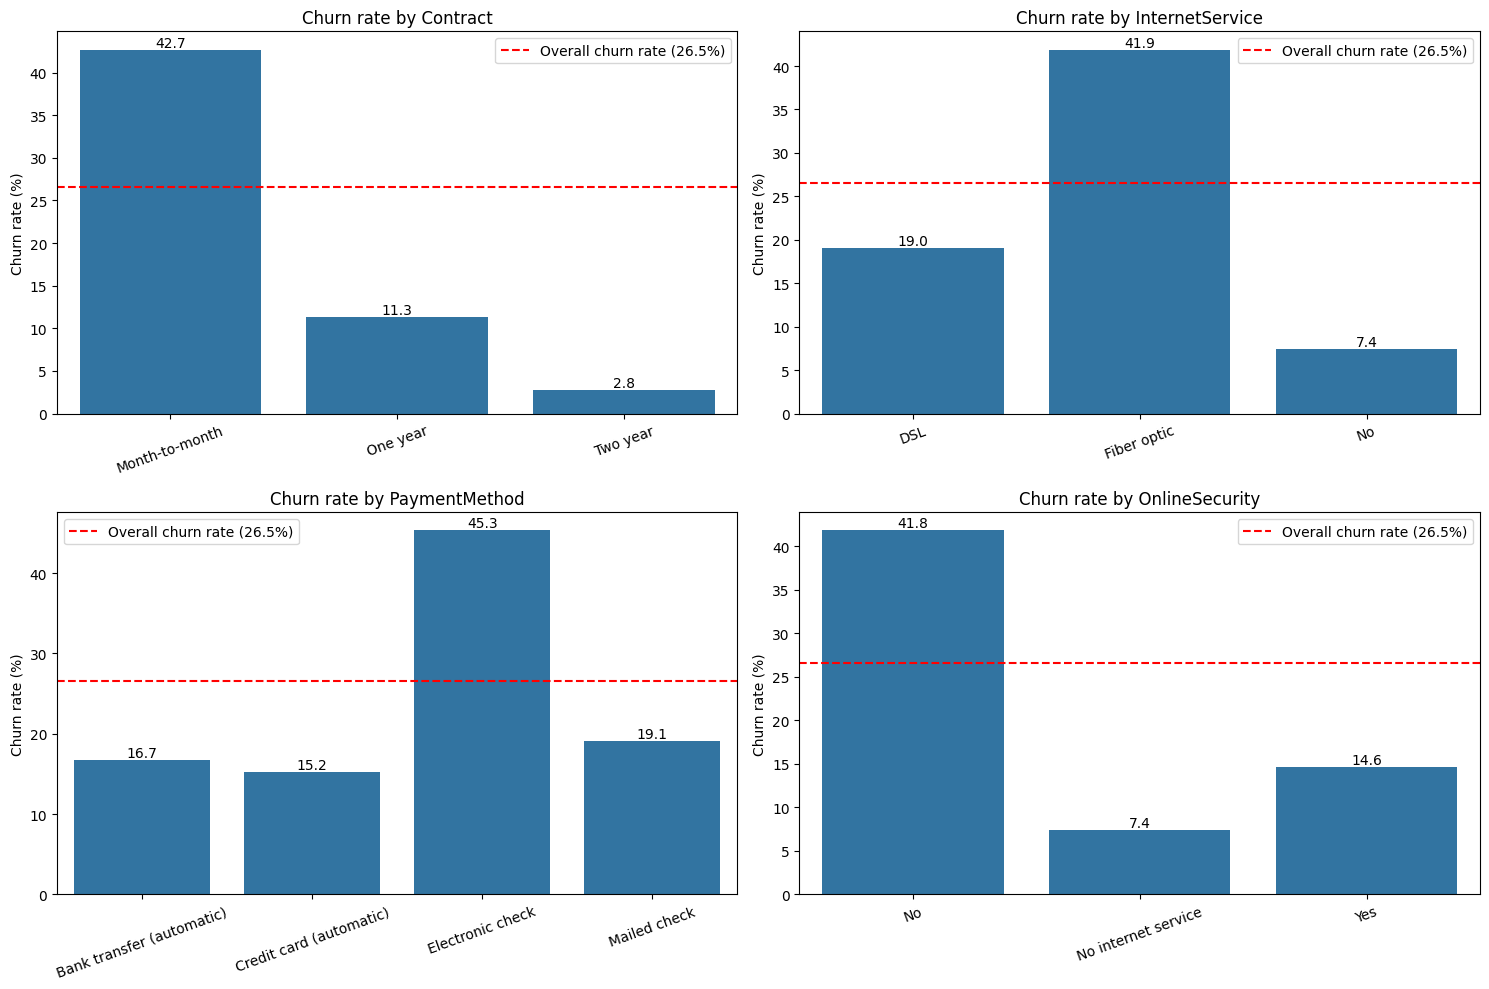

In [ ]:
#store categorical attributes with a strong association with churn in a variable
key_categorical_variables = ['Contract', 'InternetService', 'PaymentMethod', 'OnlineSecurity']
overall_churn_rate = churn_flag.mean()*100

#create subplots
fig, axes = plt.subplots(2,2, figsize=(15,10))
axes = axes.flatten()

#loop through each key categorical variable
for ax, column in zip(axes, key_categorical_variables):
  rates = churn_rate_table[churn_rate_table['Variable'] == column]
  sns.barplot(data=rates, x='Category', y='churn_rate %', ax=ax)
  ax.axhline(overall_churn_rate, color='red', linestyle='--', label=f'Overall churn rate ({overall_churn_rate:.1f}%)')#create dashed line at the overall churn rate
  ax.bar_label(ax.containers[0], fmt='%.1f')
  ax.legend()
  ax.set_title(f'Churn rate by {column}')
  ax.set_xlabel('')
  ax.set_ylabel('Churn rate (%)')
  ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

The above charts display the churn rate of each of our four top categorical features, with the red dashed line marking the overall churn rate (26.5%), making it easier to see which categories churn more than the overall churn rate and which groups churn less. For the attribute “Contract” customers on a month-to-month contract had the highest churn rate of 42.7%, which was much higher than customers on one-year contracts (11.3%) or two-year contracts (2.8%), thus emphasising our earlier observation that the longer the contract, the less likely customers are to leave. For the attribute “InternetService”, customers with fibre optic displayed the highest churn rate (41.9%) compared to Digital subscriber line (DSL) (19%) and customers who had no internet service (7.4%). Regarding the attribute “PaymentMethod”, customers who paid using electronic check displayed the highest churn rate (45.3%), which is more than double the closest payment category, which was mailed check, which had a churn rate of 19.1%. Customers using credit card payment displayed the lowest churn rate based on the Payment Method attribute. For the attribute “OnlineSecurity”, customers without online security displayed the highest churn rate (41.8%), while customers who have online security had a churn rate of 14.6%. Customers who had no internet service had the lowest churn rate for this attribute at 7.4%.

In [ ]:
#compare churn rates for each internet add-on among internet customers only
#(customers without internet service are excluded)
internet_customers = df_clean[df_clean['InternetService'] != 'No']

addon_rows = []
for column in ['OnlineSecurity', 'TechSupport', 'OnlineBackup',
               'DeviceProtection', 'StreamingMovies', 'StreamingTV']:
    #churn rate (%) for customers without and with the add-on
    rate_without = (internet_customers.loc[internet_customers[column] == 'No', 'Churn'] == 'Yes').mean() * 100
    rate_with = (internet_customers.loc[internet_customers[column] == 'Yes', 'Churn'] == 'Yes').mean() * 100

    addon_rows.append({'Add-on service': column,
                       'Churn rate without service (%)': rate_without,
                       'Churn rate with service (%)': rate_with,
                       'Difference (percentage points)': rate_without - rate_with})

addon_table = pd.DataFrame(addon_rows).round(1)
addon_table

,Add-on service,Churn rate without service (%),Churn rate with service (%),Difference (percentage points)
0,OnlineSecurity,41.8,14.6,27.2
1,TechSupport,41.6,15.2,26.5
2,OnlineBackup,39.9,21.5,18.4
3,DeviceProtection,39.1,22.5,16.6
4,StreamingMovies,33.7,29.9,3.7
5,StreamingTV,33.5,30.1,3.5


Because the six internet add-on variables also contained a “No Internet Service” category, their churn rates were compared among internet customers only (Table 4.3) in order to see the effect of each add-on more clearly. Customers without online security or technical support had a churn rate of approximately 42% compared with approximately 15% for customers who had these services. For streaming services (StreamingTV and StreamingMovies), the difference was less than four percentage points, meaning that their relationship with churn in Table 4.2 (V = 0.23) was mainly caused by the low churn rate of customers without internet service.

**Correlation analysis for numeric variables**
<BR>
Numeric variables correlation analysis will be performed on:
* Tenure
* MonthlyCharges
* TotalCharges


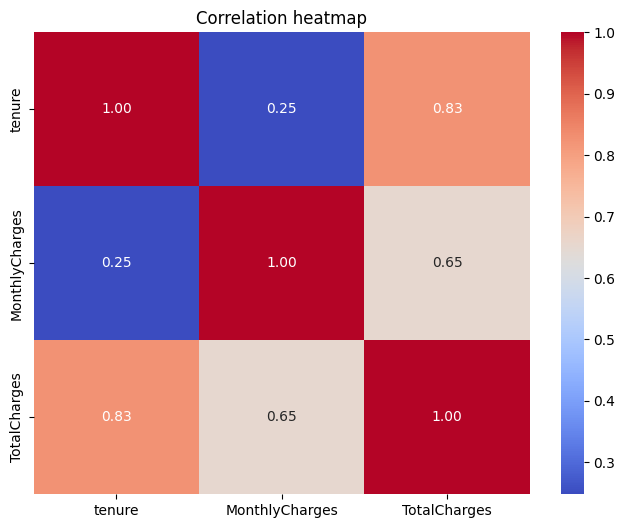

In [ ]:
#perform correlation (Pearson) on numeric columns
corr = df_clean[numeric_columns].corr()

#correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation heatmap')
plt.show()

Tenure and TotalCharges have a strong positive correlation (0.83). This makes sense because customers who stay longer have paid for more months, so their total charges are higher. Due to the strong relationship between tenure and TotalCharges, using both in our models could result in multicollinearity thus, it may be best to only keep one when developing models. MonthlyCharges and TotalCharges have a moderate positive correlation (0.65), meaning customers with higher monthly bills also tend to have higher total charges. Tenure and MonthlyCharges have a weak positive correlation (0.25), which means how long a customer stays has little connection to how much they pay each month.

In [ ]:
# Pearson: straight-line relationships
print("Pearson correlation:")
print(df_clean[numeric_columns].corr(method='pearson').round(2))

# Spearman: rank-based, less affected by skewed variables such as TotalCharges
print("\nSpearman correlation:")
print(df_clean[numeric_columns].corr(method='spearman').round(2))

Pearson correlation:
                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00

Spearman correlation:
                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.28          0.89
MonthlyCharges    0.28            1.00          0.64
TotalCharges      0.89            0.64          1.00


Because TotalCharges was strongly right-skewed, Spearman's rank correlation was also calculated as a check, since Pearson's correlation can be distorted by skewed data.

# **DATA PREPARATION**

<BR>
This section will entail:

* Handling categories such as "No Internet Service", and "No Phone Service"
* Encoding (converting categorical variables into numbers)
* Splitting the data (Train/Test split)
* Scaling data (only on the training set)

In [ ]:
#recoding "No internet service" and "No phone service" to "No"
#create a copy of the dataframe to perform recoding
df_prep = df_clean.copy()

#replace "No internet service" in the internet add-on columns it appears in
internet_addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
for column in internet_addons:
  df_prep[column] = df_prep[column].replace('No internet service', 'No')

#replace "No phone service" in the Multiple lines column
df_prep['MultipleLines'] = df_prep['MultipleLines'].replace('No phone service', 'No')
print('Before recoding:')
for column in internet_addons + ['MultipleLines']:
  print(f'{column}: {df_clean[column].value_counts().to_dict()}')

#confirm that internet add on columns plus MultipleLines only have "Yes/No"
print('\nAfter recoding:')
for column in internet_addons + ['MultipleLines']:
  print(f'{column}: {df_prep[column].value_counts().to_dict()}')#

Before recoding:
OnlineSecurity: {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup: {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection: {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport: {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV: {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies: {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
MultipleLines: {'No': 3390, 'Yes': 2971, 'No phone service': 682}

After recoding:
OnlineSecurity: {'No': 5024, 'Yes': 2019}
OnlineBackup: {'No': 4614, 'Yes': 2429}
DeviceProtection: {'No': 4621, 'Yes': 2422}
TechSupport: {'No': 4999, 'Yes': 2044}
StreamingTV: {'No': 4336, 'Yes': 2707}
StreamingMovies: {'No': 4311, 'Yes': 2732}
MultipleLines: {'No': 4072, 'Yes': 2971}


A copy of the cleaned dataset (df_prep) was created so that df_clean, which we used for EDA, remains unchanged. In the six internet add-on columns (OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV and StreamingMovies), the value "No internet service" was replaced with "No". In the MultipleLines column, "No phone service" was replaced with "No".  This was done since a customer without internet cannot have internet add-on packages, while a customer without phone service cannot have multiple lines, thus in practice, both instances mean “No”. The before and after recoding counts confirmed that the recording worked. Importantly, information is not lost since customers who have no internet service and phone service are still recorded in the InternetService column and PhoneService column.

In [ ]:
#Encoding (converting categorical variables into numbers)
#encode binary columns (Yes/No) into 1/0
binary_columns = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'Churn']
for column in binary_columns:
  df_prep[column] = df_prep[column].map({'Yes': 1, 'No': 0})

#mapping binary column (gender) and renaming the column
df_prep['gender'] = df_prep['gender'].map({'Male': 1, 'Female': 0})
df_prep = df_prep.rename(columns={'gender': 'gender_Male'})

#one hot encoding for multi category columns
df_prep = pd.get_dummies(df_prep, columns=['InternetService', 'Contract', 'PaymentMethod'], dtype=int)

#drop customerID as it offeres no predictive meaning
df_prep = df_prep.drop(columns='customerID')

#Verify changes have taken place
print(f'Shape before changes: {df_clean.shape}')
print(f'Shape after changes: {df_prep.shape}')
df_prep.head()

Shape before changes: (7043, 21)
Shape after changes: (7043, 27)


,gender_Male,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,0,1,0,1,0,0,0,0,1,0


Binary values were mapped to 1 and 0 (including gender which had Male/Female). One hot encoding was used for multi category variables ('InternetService', 'Contract', 'PaymentMethod'), with all categories retained (i.e. did not use drop_first = True) in order to support clearer SHAP interpretation. The column customerID was removed since it provided no predictive meaning.

# **CUSTOMER SEGMENTATION - K Means clustering**

Selection of segmentation variables:
<br>
Because K-Means clustering will group customers using distance calculations, it is best to use continuous or ordinal variables. Performing clustering on all 26 encoded predictor columns was not feasible, since our dataset has many binary columns, which would go on to dominate the distance calculations (since they only consist of 0 or 1), thus producing segments that are difficult to interpret and distinguish. The solution was to create a curated set of four behavioural variables for our segmentation: tenure, MonthlyCharges, number of services subscribed, and contract length (which would be converted into an ordinal variable, with 0 = month=to=month, 1 = one year, 2 = two years). TotalCharges was not included due to its high correlation with tenure, while churn being the target variable, was also not included, as customer segmentation was based on reflecting the characteristics of customers. While demographic variables and the individual services were not used during segmentation, they will be used later to profile and describe customers belonging to the different segments.  

In [ ]:
#create new dataframe that holds the four segmentation variables, keep orginal index from df_prep so customers retain their row position
segment_df = pd.DataFrame(index=df_prep.index)

#add the two numerical columns (tenure and MonthlyCharges)
segment_df['tenure'] = df_prep['tenure']
segment_df['MonthlyCharges'] = df_prep['MonthlyCharges']

#create variable that stores service columns
service_columns = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

#handle InternetService_No column that if 1 means has internet, while 0 means no internet
has_internet = 1 - df_prep['InternetService_No']

#add number of services column (including has_internet), which adds total services for each customer
segment_df['number_of_services'] = df_prep[service_columns].sum(axis=1) + has_internet

#add contract length column which maps values from the Contract column into an ordinal variable
segment_df['contract_length'] = df_clean['Contract'].map({'Month-to-month': 0, 'One year': 1, 'Two year': 2})

#perform check on newly created dataframe
print('Snippet of segment dataframe to be used for segmentation:')
print(segment_df.head())
print('\nMissing values:', segment_df.isnull().sum().sum())
print('\nSummary of segmentation variables:')
print(segment_df.describe().round(2).T)
print('\nCount of customers by number of services:')
print(segment_df['number_of_services'].value_counts().sort_index())




Snippet of segment dataframe to be used for segmentation:
   tenure  MonthlyCharges  number_of_services  contract_length
0       1           29.85                   2                0
1      34           56.95                   4                1
2       2           53.85                   4                0
3      45           42.30                   4                1
4       2           70.70                   2                0

Missing values: 0

Summary of segmentation variables:
                     count   mean    std    min   25%    50%    75%     max
tenure              7043.0  32.37  24.56   0.00   9.0  29.00  55.00   72.00
MonthlyCharges      7043.0  64.76  30.09  18.25  35.5  70.35  89.85  118.75
number_of_services  7043.0   4.15   2.31   1.00   2.0   4.00   6.00    9.00
contract_length     7043.0   0.69   0.83   0.00   0.0   0.00   1.00    2.00

Count of customers by number of services:
number_of_services
1    1264
2     859
3     846
4     965
5     922
6     908
7     6

A new dataframe (segment_df) was created to store the four segmentation variables, using the same index as df_prep in order to ensure that cluster labels can be matched back to the correct customers. Since tenure and MonthlyCharges are already numeric and continuous, they were copied directly from df_prep. The variable “number_of_services” was created by adding up the phone and internet service add-on services, including if customers had internet_service. The variable “contract_length” was created by converting the categorical variables in the “Contract” column into ordinal variables (0 = month-to-month, 1=one year, 2 = two years).  Various checks were performed on the segmentation DataFrame such as missing values, with the dataframe made up of 7043 rows with no missing values. Tenure ranges from 0  to 72 months, with an average of 32 months, while MonthlyCharges ranged from 18.25 to 118.75, with an average of 64.76, with both columns showing large variation. Customers had a minimum of one service and a maximum of nine services, with the average number of services being four. From the number of services, we see a large concentration of customers with only one service (1264 customers) while very few customers with all nine services. The contract length column has a mean of 0.69 and a median of 0, which suggests that more than half of the customers are on a month-to-month contract, with month-to-month contract customers having displayed high churn risk among the various contract types.

<BR>

Because the variables are measured on different scales, i.e. contract length goes up to 2, number of services goes up to nine, while tenure goes up to 72 and MonthlyCharges goes up to 118, we would need to standardise the variables before performing K-means clustering, since the larger variables such as MonthlyCharges and Tenure would dominate the distance calculations used by K-means.  


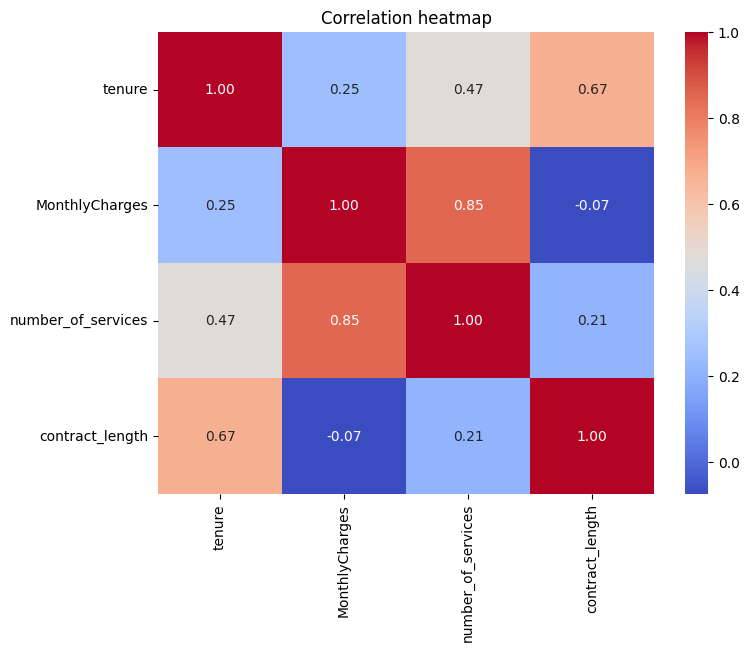

In [ ]:
#correlationn of the segmentation variables
corr = segment_df.corr()

#correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation heatmap')
plt.show()

* Tenure and MonthlyCharges (0.25) have a weak positive relationship
* Tenure and number_of_services (0.47)have moderate positive relationship, suggesting that cusomters that stay longer tend to have more services.  
* Tenure and contract_length (0.67) have strong relationship , suggesting that customers on longer contracts tend to have been with the company much longer.
* MonthlyCharges and number_of_services (0.85) have a very stong positive relationship, which is expected as the more services a customer is subscribed too the more they will pay monthly.
* MonthlyCharges and contract_length (-0.07) have no relationship
* number_of_services and contract_length (0.21) have a weak positive relationship, suggesting that customers on longer contracts have slighly more services that they are subscribed too.

<BR>

Interestingly, this very strong postive relationship between MonthlyCharges and number_of_services is similar to the strong relationship between Tenure and TotalCharges (0.83) observed earlier When doing a correlation of the numerical columns. For correlation analysis, we set a threshold of >0.8. Since our rule was that if a pair has a correlation above 0.8, one of the variables in the pair would need to be dropped (hence Total Charges was dropped in the intial correlation analysis of mumerical columns), so that the same rule would need to apply here since MonthlyCharges and number_of_services had a correlation of 0.85, thus suggesting redundancy. Moving forward to segmentation, we would then drop "number_of_services" as MonthlyCharges showed clearer patterns in the EDA


In [ ]:
#standardising the selected segmentation variables
#import StandardScaler from scikit-learn
from sklearn.preprocessing import StandardScaler

#store selected segmentation attributes into a variable
segmentation_features = ['tenure', 'MonthlyCharges', 'contract_length']

#create scaler
segment_scaler = StandardScaler()

#fit the scaler
X_segment_scaled = segment_scaler.fit_transform(segment_df[segmentation_features])

#confirm that scaling was performed (mean should be approximately 0, standard deviation should be 1)
print(f'Mean after scaling: {X_segment_scaled.mean(axis=0).round(2)}')
print(f'Standard deviation after scaling: {X_segment_scaled.std(axis=0).round(2)}')

Mean after scaling: [-0. -0. -0.]
Standard deviation after scaling: [1. 1. 1.]


Before performing segmentation, the three selected variables (tenure, MonthlyCharges and contract_length) were standardised using StandardScaler. Standardisation was performed since the three variables are measured on different scales (tenure goes up to 72, MonthlyCharges up to 118.75, contract length only up to 2), and since k means will group customers based on distance, variables with larger values would have more influence on the clusters hence standardisation required. A check confirmed that standardisation was successfully performed, with each of the three variables now having a mean of approximately 0 and a standard deviation of 1.

**Testing different values of k to find ideal k value**

In [ ]:
#determine ideal number of clusters (k value) using elbow method and silhouette score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

#set k values
k_values = range(2,11)

#empty list to store the inertia for each k
inertia_values = []

#empty list to store silhouette score for each k
silhouette_values = []

#for loop for each k and store its inertia and silhouette score
for k in k_values:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

  #fit the model to scaled data and assign each customer a cluster number
  cluster_labels = kmeans.fit_predict(X_segment_scaled)

  #store inertia
  inertia_values.append(kmeans.inertia_)

  #store silhouette score
  silhouette_values.append(silhouette_score(X_segment_scaled, cluster_labels))

#create a table showing the results for each k
k_results = pd.DataFrame({'k': k_values, 'Inertia': np.round(inertia_values, 1), 'Silhouette Score': np.round(silhouette_values, 3)})

#display the table
print(k_results)


    k  Inertia  Silhouette Score
0   2  11759.0             0.420
1   3   8366.8             0.418
2   4   5909.7             0.398
3   5   4684.6             0.402
4   6   3975.0             0.411
5   7   3398.6             0.419
6   8   3055.5             0.427
7   9   2762.3             0.407
8  10   2480.7             0.410


Inertia measured how close customers are to the centre of their assigned cluster, with lower inertia values indicating tighter clusters. Inertia was highest at k = 2 (11759) and lowest at k = 10 (2481), dropping sharply up to k = 4 and then decreasing more gradually, suggesting an elbow at around k = 3 to k = 4. Because inertia always decreases as k increases, it cannot identify the best k on its own, so the silhouette score was also used to helpchoose the best k value. The silhouette score measured separated the clusters are, ranging from -1 to 1, with higher values indicating clearer clusters. For all k values tested, the silhouette score fell between 0.40 and 0.43, indicating a moderate cluster structure. The highest silhouette score was observed at k = 8 (0.427), followed by k = 2 (0.420) and k = 3 (0.418), while the lowest was at k = 4 (0.398).

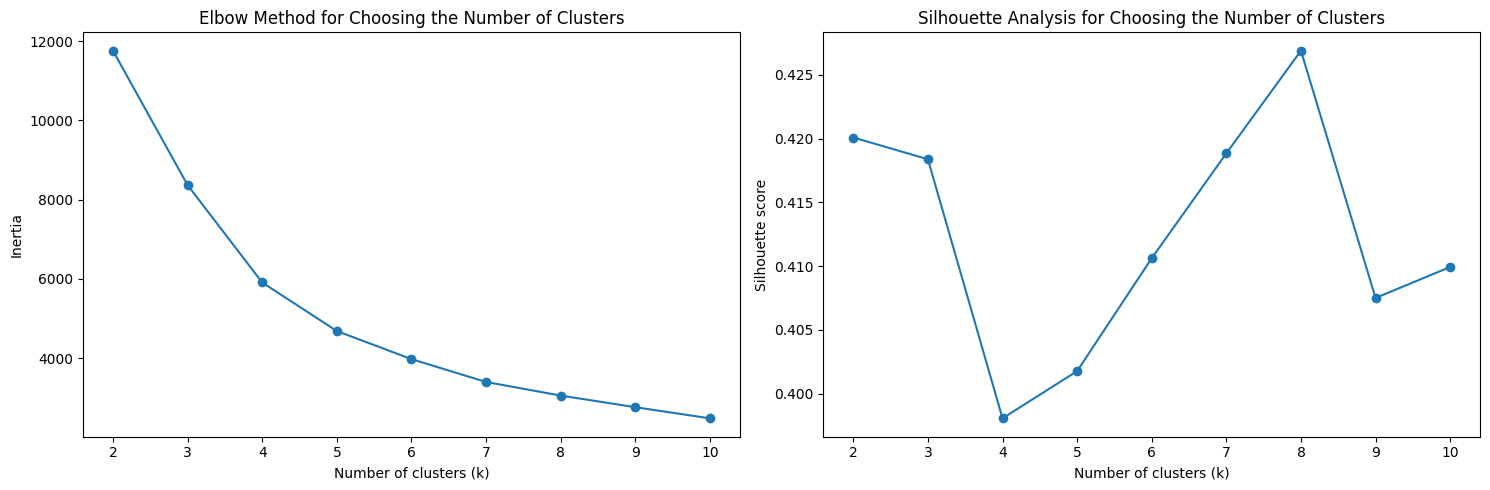

In [ ]:
#choosing best k value by plotting the elbow method and silhouette scores

#create a figure with two plots
fig, axes = plt.subplots(1,2, figsize=(15,5))

#elbow plot
axes[0].plot(list(k_values), inertia_values, marker='o')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Method for Choosing the Number of Clusters')

#silhouette plot
axes[1].plot(list(k_values), silhouette_values, marker='o')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette Analysis for Choosing the Number of Clusters')

#tight layout
plt.tight_layout()

#show
plt.show()

The elbow plot shows that inertia values dropped sharply as k increased from 2 to 4, after which the decrease became more gradual as k increased.  This points to an elbow at around k = 3 and k = 4, meaning that adding more clusters beyond this point only gives small improvements in terms of how customers are grouped. The silhouette score plot showed that scores fell between 0.40 and 0.43, indicating a weak-to-moderate cluster structure. The highest silhouette score was observed at k = 8 (0.427), followed by k = 2 (0.420) and k = 3 (0.418), while the lowest was at k = 4 (0.398). While k = 8 achieved the highest silhouette score, 8 segments/clusters would be difficult to interpret, and the score is only slightly higher than k = 3. Similarly, k = 2 would produce segments which are too broad, Therefore, taking both methods into consideration, k = 3 and k = 4 have been identified as suitable candidates since, the elbow method favoured k = 4, while the silhouette score favoured k =3. The two k values (3 and 4) will be further explored in order to detemine the final number of clusters for our customers.

In [ ]:
#profile k=3 and k=4 to detemine the best value

#create a helper column (month_to_month) where the value is 1 if customer is on a month to month contract and 0 otherwise
segment_df['month_to_month'] = (segment_df['contract_length'] == 0).astype(int)

#compare clusters for k = 3 and k = 4
for k in [3, 4]:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

  #fit the model to scaled data and assign each customer a cluster number
  labels = kmeans.fit_predict(X_segment_scaled)

  #create copy of segment_df and add the cluster labels as well as churn
  profile_df = segment_df.copy()
  profile_df['cluster'] = labels
  profile_df['churn'] = df_prep['Churn']

  #calculate the average of each variable for each cluster
  profile = profile_df.groupby('cluster').mean()

  #convert month_to_month and churn into percentages
  profile['month_to_month'] = profile['month_to_month'] * 100
  profile['churn'] = profile['churn'] * 100

  #add number of customers in each cluster
  profile['customers'] = profile_df['cluster'].value_counts().sort_index()
  print()
  #round all values to two decimal places after converting into percentages
  profile = profile.round(2)

  #display the results
  print('Results for k =', k)
  print(profile)


Results for k = 3
         tenure  MonthlyCharges  number_of_services  contract_length  \
cluster                                                                
0         59.20           90.97                6.71             1.31   
1         14.89           64.12                3.57             0.05   
2         42.21           28.14                2.00             1.59   

         month_to_month  churn  customers  
cluster                                    
0                 15.29  12.83       1956  
1                 95.12  42.31       3753  
2                  0.45   2.25       1334  

Results for k = 4
         tenure  MonthlyCharges  number_of_services  contract_length  \
cluster                                                                
0         61.16           90.65                6.88             1.55   
1         11.27           34.96                2.16             0.16   
2         22.23           83.60                4.65             0.08   
3         47.46      

To decide the best k value, K-means was fitted to both k = 3 and k = 4, and the average characteristics of each cluster was calculated and compared.

For k = 3, our three clusters were:
* (cluster 0)	Which points to long standing, high spending customers who are subscribed to many services and have a low churn rate (12.83%)
* (cluster 1)	Points to newer customers mostly on month-to-month contracts (95.12%) with a high churn rate (42.31%)
* (cluster 2)	Points to long standing customers, who are low spenders subscribed to fewer services, have long-term contracts (since month-to-month  = 0.45%) and very low churn rate (2.25%)

<BR>

For k = 4, Clusters 0 and 3 at k = 4 resemble the same groups as clusters 0 and 2 at k = 3. Cluster (1) points to low spending customers, who have an average tenure of 11 months and monthlycharges of 34.96, with an average churn of 26.96%), while cluster 2 points to high spending customers mostly on month-to-month contracts (92.12%) with a high churn rate (46.89%).



**K = 4 was selected as the final choice for k**. While k = 3 achieved a slightly higher silhouette score (0.418 compared with 0.398), k = 4 was chosen due to the elbow method and because it produced four distinct and interpretable customer segments, with none of the segments smaller than 16% of customers. Importantly, k = 4 enabled us to separate the large at risk segment from k = 3 (cluster 1) into two segments which display different characteristics and churn rates, which will help us move forward in developing segment-specific retention strategies.


In [ ]:
#fit the model after determining the best value for k, which was 4
final_k = 4

#create and fit final KMeans Model on the scaled segmentation features
kmeans_final = KMeans(n_clusters=final_k, random_state=42, n_init=10)
segment_labels = kmeans_final.fit_predict(X_segment_scaled)

#store labels as a series with the same index ad our segment_df
segment_labels = pd.Series(segment_labels, index=segment_df.index, name = 'segment')

#add the labels to segment_df
segment_df['segment'] = segment_labels

#display the number of customers per segment
print('Cusotomers per segment:')
print(segment_df['segment'].value_counts().sort_index())

#display the silhouette score
print('\nSilhouette score for k = 4:', round(silhouette_score(X_segment_scaled, segment_labels), 3))

Cusotomers per segment:
segment
0    1582
1    1695
2    2640
3    1126
Name: count, dtype: int64

Silhouette score for k = 4: 0.398


In [ ]:
#get the centroids (i.e. typical customers) for each segment
#convert the centroids from scaled units back into the original units
centroids_original = segment_scaler.inverse_transform(kmeans_final.cluster_centers_)

#store centroids into a dataframe
centroids_df = pd.DataFrame(centroids_original, columns=segmentation_features).round(2)

#name the index 'segment'
centroids_df.index.name = 'segment'

#display the dataframe
centroids_df

,tenure,MonthlyCharges,contract_length
segment,,,
0,61.16,90.61,1.55
1,11.27,34.96,0.16
2,22.23,83.60,0.08
3,47.44,29.04,1.71


The centroids represent the typical customers in each segment, with the above code displaying the averages of the segmentation variables in the various segments. Segment 0 points to loyal, high spending customers on long term contracts (tenure is approximately 61 months, monthly charges 90.61 and contract length 1.55, i.e. mostly 2-year contracts). Segment 1 points to newer, low spending customers on short-term contracts (tenure is approximately 11 months, monthly charges 34.96 and contract length 0.16 i.e. mainly month-to-month contracts). Segment 2 points to newer, high spending customers on short-term contracts (tenure is approximately 22 months, monthly charges 83.60 and contract length 0.08, i.e. mainly month-to-month contracts). Segment 3 points to loyal/long standing, low spending customers on long term contracts (tenure is approximately 47 months, monthly charges 29.04 and contract length 1.71, i.e. mostly 2-year contracts)

In [ ]:
#build the final profile table describing each of the four segments

#create a copy of segment_df
core_df = segment_df.copy()

#add churn to the core_df
core_df['churn'] = df_prep['Churn']

#group customers by segment and calculate the average of each selected variable
core_profile = core_df.groupby('segment')[['tenure', 'MonthlyCharges', 'number_of_services', 'month_to_month','churn']].mean()

#convert month_to_month and churn into percentages
core_profile['month_to_month'] = core_profile['month_to_month'] * 100
core_profile['churn'] = core_profile['churn'] * 100

#add the number and percentage of customers in each segment
core_profile['customers'] = segment_labels.value_counts().sort_index()
core_profile['% customers'] = core_profile['customers']/len(segment_labels) * 100

#round all values to 2 decimal places after converting into percentages
core_profile = core_profile.round(2)
#display the results
core_profile


,tenure,MonthlyCharges,number_of_services,month_to_month,churn,customers,% customers
segment,,,,,,,
0,61.16,90.65,6.88,1.39,9.61,1582,22.46
1,11.27,34.96,2.16,83.78,26.96,1695,24.07
2,22.23,83.60,4.65,92.12,46.89,2640,37.48
3,47.46,29.09,2.13,0.09,1.95,1126,15.99


The above table provides a summary of the typical characteristics of each of the customer segments as well as including the churn rate and the size of the segment. Segment 0 (Long standing-premium customers) accounted for 22.46% of customers, with the average tenure being 61 months, monthlyCharges at 90.65, a high number of services subscribed and low churn rate (9.61%). Segment 1 (new- low spending customers) accounted for 24.07% of customers, with the average tenure being 11 months, low MonthlyCharges at 34.96, subscribed to few services, with most customers on month-to-month contracts and a churn rate of 26.96. Segment 2 (high spending high churn rate customers) accounted for 37.48% of customers (largest group), with the average tenure being 22 months, high MonthlyCharges at  83.60, and a moderate number of services, with most customers on a month-to-month contract and having the highest churn risk at 46.89%. Segment 3 (long-standing basic-services customers) accounted for 15.99% of customers (smallest group), with an average tenure of 47 months, lowest MonthlyCharges at 29.09, few services and most customers on long term contracts instead of month-to-month, with this segment having the lowest churn risk (1.95%).

In [ ]:
#store descriptor variables which were not used for building our segments into a variable
descriptor_variables = ['SeniorCitizen', 'Partner', 'Dependents', 'gender_Male', 'InternetService_DSL', 'InternetService_Fiber optic',
                        'InternetService_No', 'OnlineSecurity', 'TechSupport', 'OnlineBackup', 'DeviceProtection', 'StreamingTV',
                        'StreamingMovies', 'PaperlessBilling', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check','PaymentMethod_Bank transfer (automatic)',
                        'PaymentMethod_Credit card (automatic)', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year']

#group customers by segment and calculate the average of each variable
descriptor_profile = df_prep[descriptor_variables].groupby(segment_labels).mean()*100

#transpose the table
descriptor_profile = descriptor_profile.T

#add the overall average
descriptor_profile['Overall_average'] = df_prep[descriptor_variables].mean()*100

#round all values to 2 decimal places after converting into percentages
descriptor_profile = descriptor_profile.round(2)
#display the results
descriptor_profile

segment,0,1,2,3,Overall_average
SeniorCitizen,16.62,8.02,25.95,5.15,16.21
Partner,70.86,30.21,40.83,61.37,48.30
Dependents,36.98,27.02,19.58,48.85,29.96
gender_Male,49.87,52.57,49.20,51.15,50.48
InternetService_DSL,42.79,58.41,17.01,27.09,34.37
InternetService_Fiber optic,57.21,0.00,82.99,0.00,43.96
InternetService_No,0.00,41.59,0.00,72.91,21.67
OnlineSecurity,62.01,14.40,23.14,16.25,28.67
TechSupport,65.80,12.86,22.95,15.90,29.02
OnlineBackup,70.54,14.16,34.96,13.32,34.49


The above table provides a summary of the descriptive variables, which were not used to form our customer segments, with the variables now being used to help the different customer profiles in the different segments, with the overall average also included to indicate the overall average of each of the variables allowing us to see when the various segments are above or below the average. Segment 0 (Long standing-premium customers)  are more likely to have a Partner (70.86 vs 48.30% overall average for Partner variable), all have internet and mostly subscribe to add-on services such as OnlineSecurity and OnlineBackup. Customers in this segment tend to pay automatically either by bank transfer or credit card and rarely on month-to-month contracts, with most customers either on a one-year or two-year contract. Segment 1 (new-low spending customers) with many customers not having internet service (41.59%), while those who do have internet service they mainly use DSL (58.41). Most of the customers are subscribed to few services, less likely to have a partner, and mostly on month-to-month contracts (83.78%), with customers most likely to pay using mail check.  

<BR>

Segment 2 (high spending flexible customers) had the highest share of SeniorCitizens (25.95%), tend to have internet service with fiber optic (82.99%) being the popular choice, with streamingTv and streamingMovies being popular add-ons for this segment. Most of the customers in this segment are on month-to-month contracts (92.12%), with over half of the payments made by electronic check (55.45%) and most customers using paperless billing (75.38%). Segment 3 (long-standing basic-services customers)  tend to have a partner (61.37%) and dependents (48.85% vs 29.96% overall). Most of the customers in this segment tend not to have internet services (72.91%), subscribed to few services, and most tend to be on two-year contracts (70.78%).

<BR>

Segment 2 has several strong indicators such as fibre (83%), month-to-month (92%), electronic check (55%), paperless billing (75%), more senior citizens (26%) and fewer protective services, which makes it slightly difficult to determine which of these features matters most for customer churn since they occur together


**Check share of churners per segment:**

Segment 2 was the largest segment, accounting for 37.5% of customers, and had the highest churn rate at 46.9%. However, the churn rate only indicates how likely customers in a particular segment are to leave, not how many of all the customers who churned come from that segment. Below, we investigate this by counting the number of churners in each segment and calculating how much each segment contributes to overall churn.

In [ ]:
#number of churners in each segment
churners_per_segment = core_df.groupby('segment')['churn'].sum()

#percentage of each segment's share of all churn
segment_share_churn = (churners_per_segment/churners_per_segment.sum()*100).round(1)

print('Number of churners per segment:')
print(churners_per_segment)
print('\nPercentage of churners per segment:')
print(segment_share_churn)

Number of churners per segment:
segment
0     152
1     457
2    1238
3      22
Name: churn, dtype: int64

Percentage of churners per segment:
segment
0     8.1
1    24.5
2    66.2
3     1.2
Name: churn, dtype: float64


In total, there were 1869 customers who churned. Segment 2 accounted for 66.2% (1238 customers) of all churners even though it consisted of only 37.5% of our customers. This indicates that two out of every three customers who churned came from Segment 2. Segment 1 contributes 24.5% (45 customers) of churners, while Segments 0 and 3 combined contributed less than 10% (152 and 22 customers) of churn. Segments 1 and 2 combined account for over 90% of all churn, thus suggesting that retention strategies should mainly focus on these two segments, with Segment 2 being a top priority for the company.

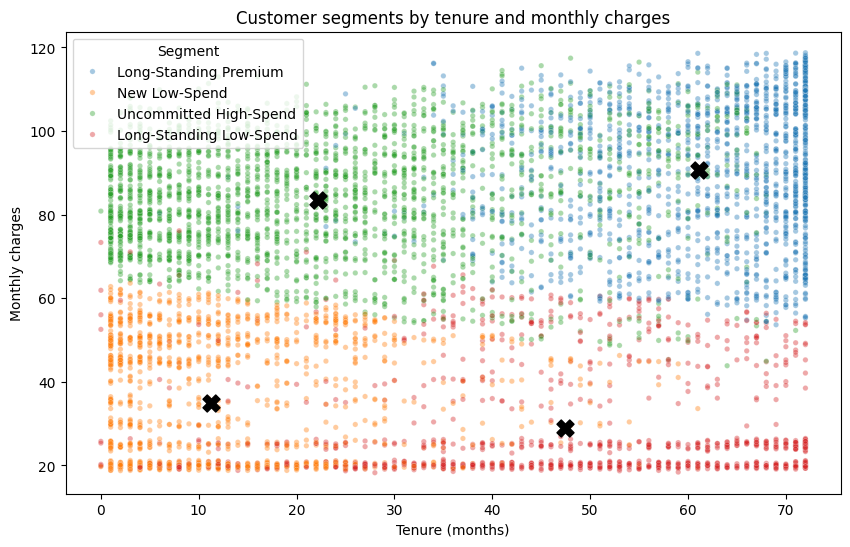

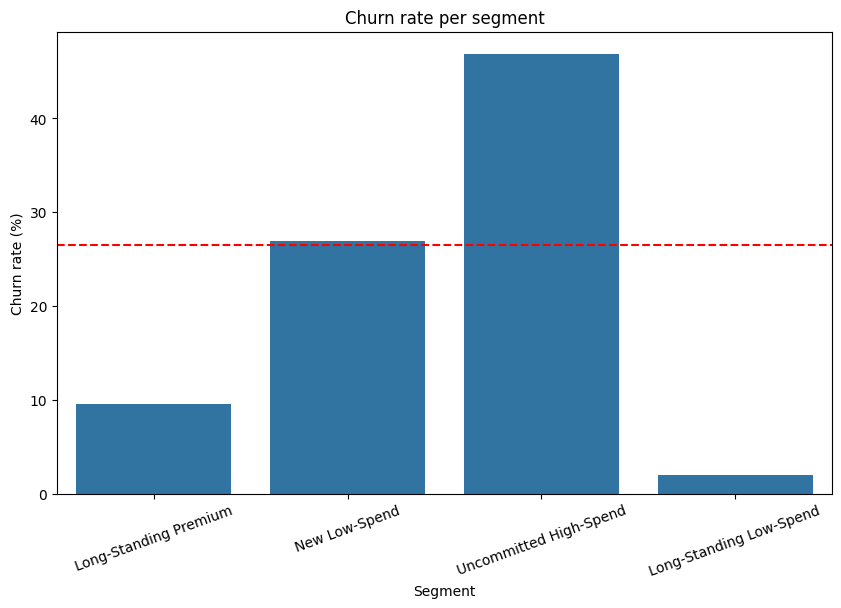

In [ ]:
#set descriptive names of segments
segment_names = {0: 'Long-Standing Premium', 1: 'New Low-Spend',
                 2: 'Uncommitted High-Spend', 3: 'Long-Standing Low-Spend'}

#add segment_name to segment_df
segment_df['segment_name'] = segment_df['segment'].map(segment_names)

#fix the order of segments so our charts show segments in the same order
name_order = [segment_names[i] for i in range(final_k)]

#make a copy of the segment data for plotting purposes and add the churn
plot_df = segment_df.copy()
plot_df['churn'] = df_prep['Churn']

#first plot - Customer segments by tenure and monthly charges
plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_df, x='tenure', y='MonthlyCharges', hue='segment_name',
                hue_order=name_order, alpha=0.4, s=15)
plt.scatter(centroids_df['tenure'], centroids_df['MonthlyCharges'],
            marker='X', s=150, color='black')  #black "X" at the average point of each segment
plt.title('Customer segments by tenure and monthly charges')
plt.xlabel('Tenure (months)')
plt.ylabel('Monthly charges')
plt.legend(title='Segment')
plt.show()
print('\n')
#second plot - Churn rate per segment
churn_by_segment = plot_df.groupby('segment_name')['churn'].mean().reindex(name_order) * 100
plt.figure(figsize=(10, 6))
sns.barplot(x=churn_by_segment.index, y=churn_by_segment.values)
plt.axhline(overall_churn_rate, color='red', linestyle='--')
plt.title('Churn rate per segment')
plt.xlabel('Segment')
plt.ylabel('Churn rate (%)')
plt.xticks(rotation=20)  #tilt the long segment names so they don't overlap
plt.show()

**Segmentation Visuals**

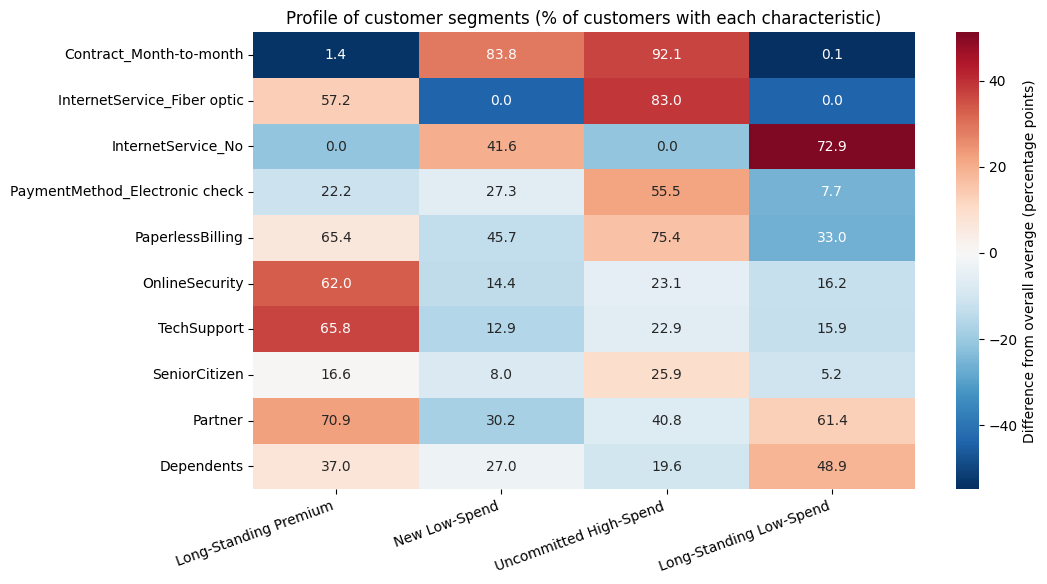

In [ ]:
#key descriptor rows to display (the most distinctive characteristics from the profile table)
key_rows = ['Contract_Month-to-month', 'InternetService_Fiber optic', 'InternetService_No',
            'PaymentMethod_Electronic check', 'PaperlessBilling', 'OnlineSecurity', 'TechSupport',
            'SeniorCitizen', 'Partner', 'Dependents']

#actual percentages for each segment (shown as the numbers in each cell)
heat_values = descriptor_profile.loc[key_rows, [0, 1, 2, 3]]

#difference from the overall average (used for the colours)
difference = heat_values.sub(descriptor_profile.loc[key_rows, 'Overall_average'], axis=0)

#use the segment names as column labels
heat_values.columns = name_order
difference.columns = name_order

#plot: colour = above (red) or below (blue) average; number = actual percentage
plt.figure(figsize=(11, 7))
sns.heatmap(difference, annot=heat_values, fmt='.1f', cmap='RdBu_r', center=0,
            cbar_kws={'label': 'Difference from overall average (percentage points)'})
plt.title('Profile of customer segments (% of customers with each characteristic)')
plt.ylabel('')
plt.tight_layout()
plt.xticks(rotation=20, ha='right')
plt.show()

The above heatmap compares the four segments across 10 key characteristics, with the number in the cell showing the percentage of customers with that characteristic in that segment. The cells were coloured to show how the values compare to the overall average of that characteristic, with red signalling above average and blue signalling below average.

Long Standing Premium Customers are characterised by their commitment (very few on month-to-month contracts (1.4%)) and subscription to extra services such as TechSupport (65.8%) and OnlineSecurity (62%). Most have a partner (70.9%), and over half use fibre optic internet (57.2%). New Low-Spend Customers are mostly on month-to-month contracts (83.8%) and have no fiber optic at all. These customers tend to be below average for add-on services and are less likely to have a partner (30.2%). Uncommitted High Spend Customers have the highest rates of month-to-month contracts (92.1%), most have fibre optic internet (83.0%) being the popular choice, electronic check payments (55.5%) and paperless billing (75.4%), and they include the largest portion of senior citizens (25.9%).  While these customers all have internet, add-on services such as TechSupport and Online Security were low. Long Standing Low Spend Customers are almost all were on one or two-year contracts (99.9%), with most customers not having internet service (72.9%), and tend to be the most family-oriented segment with the highest share of dependents (48.9%) and many customers having partners (61.4%).


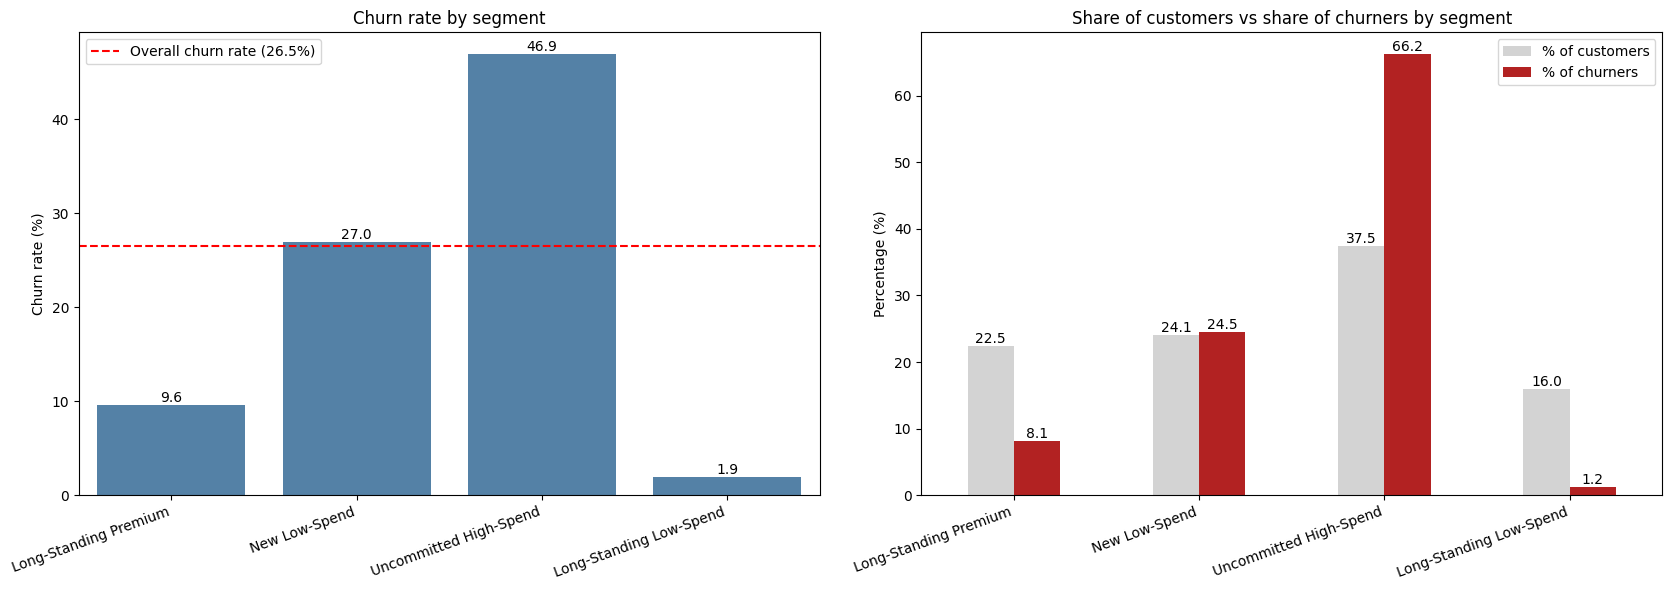

In [ ]:
#combine each segment's share of customers and share of churners
concentration = pd.DataFrame({
    '% of customers': core_profile['% customers'],
    '% of churners': segment_share_churn
})
concentration.index = name_order

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

#panel 1: churn rate per segment
churn_by_segment = core_profile['churn']
churn_by_segment.index = name_order
sns.barplot(x=churn_by_segment.index, y=churn_by_segment.values, color='steelblue', ax=axes[0])
axes[0].axhline(overall_churn_rate, color='red', linestyle='--',
                label=f'Overall churn rate ({overall_churn_rate:.1f}%)')
axes[0].bar_label(axes[0].containers[0], fmt='%.1f')
axes[0].set_title('Churn rate by segment')
axes[0].set_xlabel('')
axes[0].set_ylabel('Churn rate (%)')
axes[0].legend()

#panel 2: share of customers vs share of churners (side-by-side bars)
concentration.plot(kind='bar', ax=axes[1], color=['lightgrey', 'firebrick'], rot=0)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.1f')
axes[1].set_title('Share of customers vs share of churners by segment')
axes[1].set_ylabel('Percentage (%)')

#tilt the segment names on both charts so they don't overlap
for ax in axes:
    ax.tick_params(axis='x', labelrotation=20)
    plt.setp(ax.get_xticklabels(), ha='right')

plt.tight_layout()
plt.savefig('fig_segment_churn_concentration.png', dpi=300, bbox_inches='tight')
plt.show()

The first chart shows the churn rate within each segment compared with the overall churn rate of 26.5% (red dashed line). Uncommitted High Spend Customers have the highest churn rate (46.9%), about 1.8 times the overall rate, followed by New Low-Spend Customers who have a churn rate of 27%.  Long-Standing Premium Customers (9.6%) and Long-Standing Low-Spend Customers (1.9%) had the lowest churn rates, suggesting that tenure and contract length are strongly linked to customer retention.

<BR>

The second chart compares each segment's share of all customers (grey) with the percentage of churners in each segment. Uncommitted High Spend Customers make up 37.5% of our customers but account for 66.2% of all churners, meaning that two out of every three customers who leave the company come from this one segment. The two long-standing segments (Long-Standing Premium Customers and Long-Standing Low-Spend Customers) together contribute fewer than 10% of churners despite making up 38.5% of customers, while the two uncommitted segments account for about 91% of all churn.



**Segments Stability check**

As part of ensuring reliability of our results, the below test will check whether our segments are stable (i.e., the same segments appear even if our data changes slightly). We will fit K-means ten times, each on a random 80% of customers, with the model assigning segments to all the customers. We will then compare the assignments with our final segments using the Adjusted Rand Index (ARI) with An ARI of 1 meaning identical groupings, and an ARI near 0 meaning no better than random.

In [ ]:
from sklearn.metrics import adjusted_rand_score

#random number generator with our fixed seed, so the samples are reproducible
rng = np.random.RandomState(RANDOM_SEED)

ari_scores = []

for i in range(10):
    #randomly select 80% of customers (without repeating anyone)
    sample_index = rng.choice(len(X_segment_scaled), size=int(0.8 * len(X_segment_scaled)), replace=False)

    #fit K-means (k = 4) on that 80% only
    kmeans_sample = KMeans(n_clusters=final_k, random_state=i, n_init=10)
    kmeans_sample.fit(X_segment_scaled[sample_index])

    #use this model to assign ALL customers to a segment
    sample_labels = kmeans_sample.predict(X_segment_scaled)

    #compare with the final segment labels (ARI ignores differences in cluster numbering)
    ari_scores.append(adjusted_rand_score(segment_labels, sample_labels))

print('ARI for each run:', np.round(ari_scores, 3))
print(f'Mean ARI: {np.mean(ari_scores):.3f}  (min {np.min(ari_scores):.3f}, max {np.max(ari_scores):.3f})')

ARI for each run: [0.967 0.993 0.978 0.986 0.981 0.975 0.989 0.998 0.985 0.977]
Mean ARI: 0.983  (min 0.967, max 0.998)


To test whether the segments are reliable, K-means was re-run 10 times on different random 80% samples of customers. Each result was compared with the final segments using the Adjusted Rand Index (ARI), with an ARI of 1 meaning identical groupings, and an ARI near 0 meaning no better than random. From our check, we see that our ARI scores ranged from 0.967 to 0.998, with a mean of 0.983, thus confirming that our segments are indeed highly stable and reflect genuine patterns found in the data.

# **CHURN PREDICTION**

<BR>

First step is to split data into train/test split using 80/20 split. Will then train four models, with the models compared in order to determine the best model. Models to be trained:
* Logistic Regression
* Decision Tree
* Random Forests
* XGBoost


In [ ]:
#we will be using our df_prep dataframe and will remove the target variable (churn)
X = df_prep.drop(columns='Churn')
y = df_prep['Churn']

#split the data into train/test split using 80/20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y)

#get the shape of train and test set
print(f'Shape of the training set: {X_train.shape} and the churn rate is: {round(y_train.mean()*100, 2)}%')
print(f'Shape of the test set: {X_test.shape} and the churn rate is: {round(y_test.mean()*100, 2)}%')
#

Shape of the training set: (5634, 26) and the churn rate is: 26.54%
Shape of the test set: (1409, 26) and the churn rate is: 26.54%


In [ ]:
#setting up cross validation which will be used by all four of our models
from sklearn.model_selection import StratifiedKFold, cross_validate

#create 5 fold stratified cross validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

#metrics to be calculated for every model
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

#dictionary to store cross validation results
cv_results = {}

# Logistic Regression

In [ ]:
#import libraries
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

#create pipeline which scales the features and fits the logistic regression model
log_reg_pipeline = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', random_state=RANDOM_SEED, max_iter=1000))

#run 5-fold cross-validation on the Training set
log_reg_cv = cross_validate(log_reg_pipeline, X_train, y_train, cv=cv, scoring=scoring)

#store results in the cv_results dictionary
cv_results['Logistic Regression'] = log_reg_cv

#display the mean and standard deviation of each metric across the 5 folds
print('Logistic Regression: 5-fold cross-validation (training set) results')
for metric in scoring:
    scores = log_reg_cv['test_' + metric]
    print(f'{metric:10}: mean = {scores.mean():.3f}, std = {scores.std():.3f}')

Logistic Regression: 5-fold cross-validation (training set) results
accuracy  : mean = 0.749, std = 0.015
precision : mean = 0.518, std = 0.019
recall    : mean = 0.801, std = 0.037
f1        : mean = 0.629, std = 0.023
roc_auc   : mean = 0.846, std = 0.012


Logistic Regression was evaluated using 5-fold stratified cross-validation on the training set. The Logistic Regression model scored a ROC-AUC score of 0.846, which shows that the model does well in separating churners from non-churners. The Logistic Regression model achieved a recall of 0.801, meaning the model correctly identified about 80% of customers who actually churned, while the model had a precision of 0.518, meaning that of the customers flagged as likely to churn, about half of the customers did actually churn. The relationship of high recall and moderate precision is the result of class weighting, which we used as a means of handling the class imblance in the dataset. The F1 score (0.629) reflects the balance between precision and recall.  Due to the class imbalance between churners and non-churners, accuracy (0.749) accuracy is less informative since simply predicting the majority class (not churning) the model would be right most of the time. The low standard deviations (all below 0.04) show that performance was consistent across folds.

In [ ]:
#fit the logistic regression pipeline on the train set
log_reg_pipeline.fit(X_train, y_train)

#extract the coefficients of features in order to see which features push churn up or down
coefficients = pd.Series(log_reg_pipeline.named_steps['logisticregression'].coef_[0], index=X_train.columns).sort_values()

print('Features most associated with lower churn probability (negative coefficients):')
print(coefficients.head(8).round(3))
print('\nFeatures most associated with higher churn probability (positive coefficients):')
print(coefficients.tail(8).round(3))

Features most associated with lower churn probability (negative coefficients):
tenure                -1.153
MonthlyCharges        -0.957
InternetService_No    -0.736
Contract_Two year     -0.342
OnlineSecurity        -0.120
Dependents            -0.104
TechSupport           -0.090
InternetService_DSL   -0.083
dtype: float64

Features most associated with higher churn probability (positive coefficients):
PaymentMethod_Electronic check    0.126
PaperlessBilling                  0.165
MultipleLines                     0.194
StreamingTV                       0.260
StreamingMovies                   0.273
Contract_Month-to-month           0.322
TotalCharges                      0.490
InternetService_Fiber optic       0.689
dtype: float64


After performing stratified cross-validation, the Logistic Regression pipeline was fitted onto the training set, and the coefficients of the different features were extracted in order to see which features push churn up or down, with negative coefficients associated with lower churn and positive coefficients associated with higher churn. We can compare the sizes of the coefficients since the features have been scaled. From the features, tenure had the largest negative coefficient (-1.153), suggesting that customers who have stayed longer with the company are less likely to leave. Other features linked to lower churn include having no internet service ( -0.736) as well as subscribing to the two-year contract (-0.342). On the other side, fiber optic internet had the largest positive coefficient (0.689)  followed by month-to-month contracts (0.322) suggesting that customers with fiber and on month to month contracts are most likely to leave.
MonthlyCharges ( -0.957), which had the second-highest negative coefficient, and TotalCharges ( 0.490), which had the second-highest positive coefficient, need to be viewed with caution since they overlap heavily with other features. For instance, TotalCharges is approximately tenure multiplied by MonthlyCharges , while MonthlyCharges is mainly determined by the add-ons a customer is subscribed to, such as fiber and streaming services. Because they are heavily influenced by other features, the individual coefficients for MonthlyCharges and TotalCharges can't be trusted on their own.


# Decision Tree

In [ ]:
#import decision tree library
from sklearn.tree import DecisionTreeClassifier

#Evaluate various tree depths
#set the tree depths to test
tree_depth_values = [2, 3, 4, 5, 6, 8, 10, None]

#variable where we will store the results of each tree depth
tree_depth_rows = []

#create decision tree (testing different tree depths)
for depth in tree_depth_values:
    tree_model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_SEED, class_weight='balanced')

    #run 5-fold cross-validation on the Training set
    tree_cv = cross_validate(tree_model, X_train, y_train, cv=cv, scoring='roc_auc', return_train_score=True)

    #store results in the tree_depth_rows
    tree_depth_rows.append({'max_depth': str(depth), 'Training ROC-AUC score': tree_cv['train_score'].mean(), 'Validation ROC-AUC score': tree_cv['test_score'].mean()})

#convert tree_depth_rows into a dataframe
tree_depth_df = pd.DataFrame(tree_depth_rows)

#add column which gets the gap between the training and validation ROC-AUC scores
tree_depth_df['ROC-AUC Gap'] = tree_depth_df['Training ROC-AUC score'] - tree_depth_df['Validation ROC-AUC score']

#round values to three decimals
tree_depth_df = tree_depth_df.round(3)

#display results
tree_depth_df


,max_depth,Training ROC-AUC score,Validation ROC-AUC score,ROC-AUC Gap
0,2,0.792,0.792,0.001
1,3,0.825,0.816,0.009
2,4,0.841,0.825,0.015
3,5,0.855,0.828,0.027
4,6,0.869,0.819,0.050
5,8,0.908,0.791,0.117
6,10,0.948,0.752,0.196
7,None,1.000,0.663,0.337


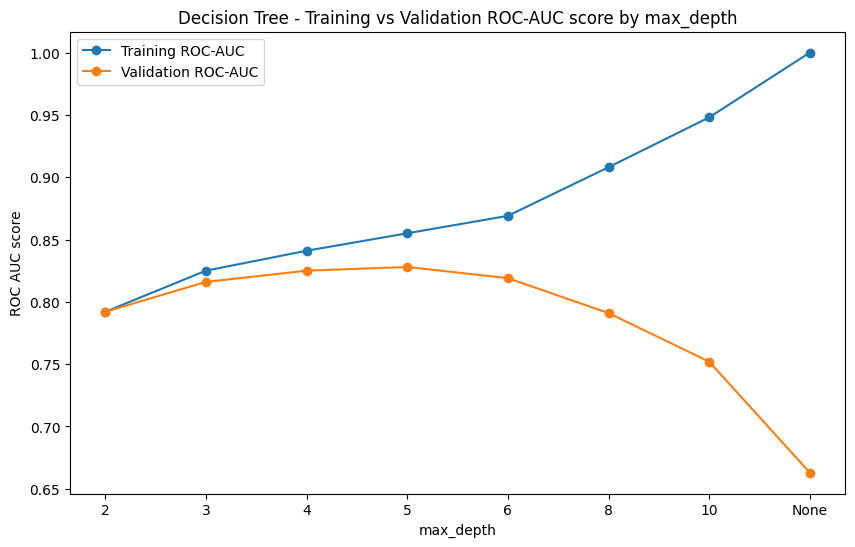

In [ ]:
#plot performance of the decision tree at different max_depth
plt.figure(figsize=(10,6))
plt.plot(tree_depth_df['max_depth'], tree_depth_df['Training ROC-AUC score'], label='Training ROC-AUC', marker='o')
plt.plot(tree_depth_df['max_depth'], tree_depth_df['Validation ROC-AUC score'], label='Validation ROC-AUC', marker='o')
plt.title('Decision Tree - Training vs Validation ROC-AUC score by max_depth')
plt.xlabel('max_depth')
plt.ylabel('ROC AUC score')
plt.legend()
plt.show()


Since a key risk of decision trees is overfitting,  different maximum depths were tested using 5-fold cross-validation, comparing the training and validation ROC-AUC scores. From the test, we see that as the tree gets deeper, the training score keeps increasing until it reached a perfect score of 1 when there was no depth limit.  The validation score peaked around a max_depth of 5 (0.828) and then began to decrease the deeper the tree got. The widening gap between the Training and Validation ROC-AUC scores is a sign of overfitting. A maximum depth of 4 was selected as it showed less overfitting compared to depth 5, with 4 having a ROC-AUC gap of 0.015 compared with 0.027 at depth 5, and a maximum depth of 4 was selected as it produces a smaller tree which is easier to interpret.  

In [ ]:
#create final decision tree using maximum depth of 4
decision_tree_model = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_SEED, class_weight='balanced')

#run 5-fold cross-validation on the Training set
decision_tree_cv = cross_validate(decision_tree_model, X_train, y_train, cv=cv, scoring=scoring)

#store results in the cv_results dictionary
cv_results['Decision Tree'] = decision_tree_cv

#fit the decision tree model on the train set
decision_tree_model.fit(X_train, y_train)

#display the mean and standard deviation of each metric across the 5 folds
print('Decision Tree: 5-fold cross-validation (training set) results')
for metric in scoring:
    scores = decision_tree_cv['test_' + metric]
    print(f'{metric:10}: mean = {scores.mean():.3f}, std = {scores.std():.3f}')

Decision Tree: 5-fold cross-validation (training set) results
accuracy  : mean = 0.738, std = 0.030
precision : mean = 0.509, std = 0.041
recall    : mean = 0.767, std = 0.051
f1        : mean = 0.609, std = 0.020
roc_auc   : mean = 0.825, std = 0.009


A decision Tree with a max_depth = 4 was evaluated using 5-fold stratified cross-validation on the training set. The Decision Tree model scored a ROC-AUC of 0.825, which shows that the model does well in separating churners from non-churners. The Decision Tree model achieved a recall of 0.767, meaning the model correctly identified about 77% of customers who actually churned, while the model had a precision of 0.509, meaning that of the customers flagged as likely to churn, about half actually churned. The relationship of high recall and moderate precision is again the result of class weighting, which we used as a way of handling the class imbalance in the dataset. The F1 score (0.609) reflects the balance between precision and recall. Due to the class imbalance between churners and non-churners, accuracy (0.738) is less informative, since a model that simply predicted the majority class (not churning) would be right most of the time. The standard deviations were low (all at or below 0.051), showing that performance was fairly consistent across the various folds. Compared with Logistic Regression, the Decision Tree performed slightly lower on every metric (ROC-AUC 0.825 vs 0.846; recall 0.767 vs 0.801).

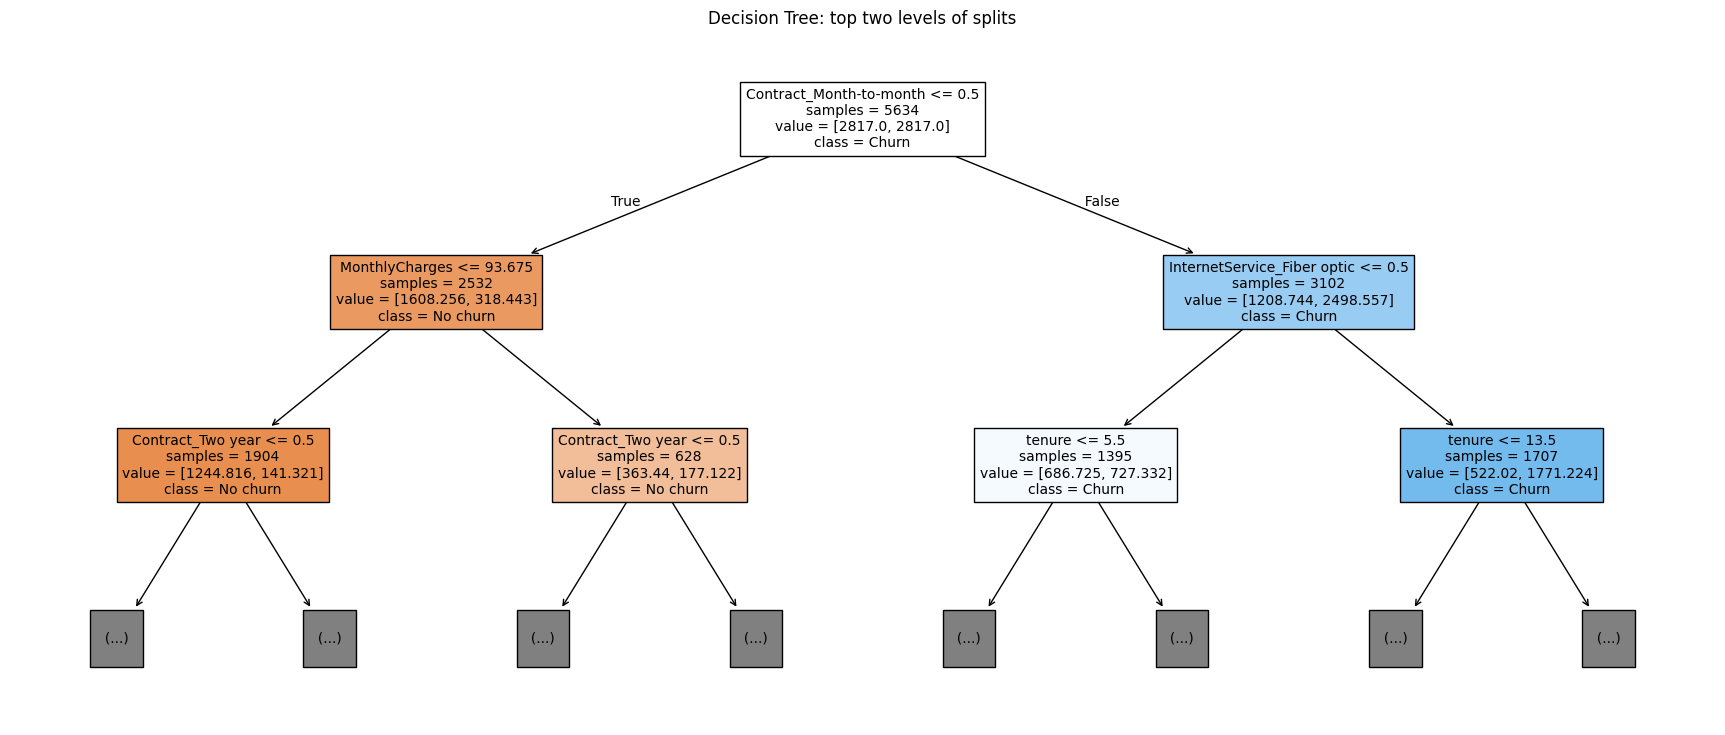

In [ ]:
from sklearn.tree import plot_tree

#draw the Decision Tree: top two levels of splits
plt.figure(figsize=(22, 9))
plot_tree(decision_tree_model,
          feature_names=X_train.columns,
          class_names=['No churn', 'Churn'],
          filled=True,
          impurity=False,
          max_depth=2,
          fontsize=10)
plt.title('Decision Tree: top two levels of splits')
plt.savefig('fig_decision_tree_top_levels.png', dpi=300, bbox_inches='tight')
plt.show()

 The above figure shows the first two levels of the Decision Tree, which highlight the most important decisions of the decision tree. Contract type was the first split, with the tree splitting customers on month-to-month contracts from those customers on longer contracts. Customers who are not on month-to-month contracts are then split using monthly charges, with customers mainly leaning towards not churning. Customers who are in month-to-month contracts are then split based on whether they have fiber optic internet, with customers then further split based on tenure. From the tree, we see that customers on month-to-month contracts and have fiber are most likely to churn. This confirms earlier finding that contract type, fiber optic internet and tenure as key drivers influencing customer churn.

In [ ]:
#feature importance - calculate how much each feature contributed to the decision tree splits
dt_feature_importance = pd.Series(decision_tree_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

#display the top important features
print('Decision Tree - Top 10 features by importance:')
print(dt_feature_importance.head(10).round(3))

#number of features the decision tree used to make its splits
print('\nNumber of features used by the decision tree: ', (dt_feature_importance >0).sum(), 'out of ', len(dt_feature_importance))

Decision Tree - Top 10 features by importance:
Contract_Month-to-month           0.654
InternetService_Fiber optic       0.116
tenure                            0.097
MonthlyCharges                    0.039
Contract_Two year                 0.028
InternetService_No                0.016
StreamingMovies                   0.014
PaymentMethod_Electronic check    0.013
PhoneService                      0.012
TotalCharges                      0.011
dtype: float64

Number of features used by the decision tree:  10 out of  26


Feature importance helped show how much each contributed to the decision tree’s splits (values add up to 1). From our features, we see that Contract_Month_to_month is the most important feature with a score of 0.654, followed by InternetService_Fiber optic (0.116) and tenure (0.097) with the top 3 features contributing 87% of total importance in the decision tree, with the remaining features contributing very little to the tree. Overall, the model used 10 of the 26 features, suggesting that the model relies on a small number of features.

# Random Forest

In [ ]:
#import random forest library
from sklearn.ensemble import RandomForestClassifier

#Evaluate various tree depths
#set the tree depths to test
rf_depth_values = [4, 6, 8, 10, 12, None]

#create variable where we will store the results of each depth
rf_depth_rows = []

#create random forest (testing different depths)
for depth in rf_depth_values:
  rf_model = RandomForestClassifier(n_estimators=300, max_depth=depth, random_state=RANDOM_SEED, class_weight='balanced', n_jobs=-1)

  #run 5-fold cross-validation on the Training set
  rf_cv = cross_validate(rf_model, X_train, y_train, cv=cv, scoring='roc_auc', return_train_score=True)

  #store results in the rf_depth_rows
  rf_depth_rows.append({'max_depth': str(depth), 'Training ROC-AUC score': rf_cv['train_score'].mean(), 'Validation ROC-AUC score': rf_cv['test_score'].mean()})

#convert rf_depth_rows into a dataframe
rf_depth_df = pd.DataFrame(rf_depth_rows)

#add column which gets the gap between the training and validation ROC-AUC scores
rf_depth_df['ROC-AUC Gap'] = rf_depth_df['Training ROC-AUC score'] - rf_depth_df['Validation ROC-AUC score']

#round values to three decimals
rf_depth_df = rf_depth_df.round(3)

#display results
rf_depth_df


,max_depth,Training ROC-AUC score,Validation ROC-AUC score,ROC-AUC Gap
0,4,0.853,0.844,0.009
1,6,0.875,0.848,0.027
2,8,0.911,0.847,0.064
3,10,0.953,0.845,0.108
4,12,0.983,0.839,0.144
5,None,1.000,0.828,0.172


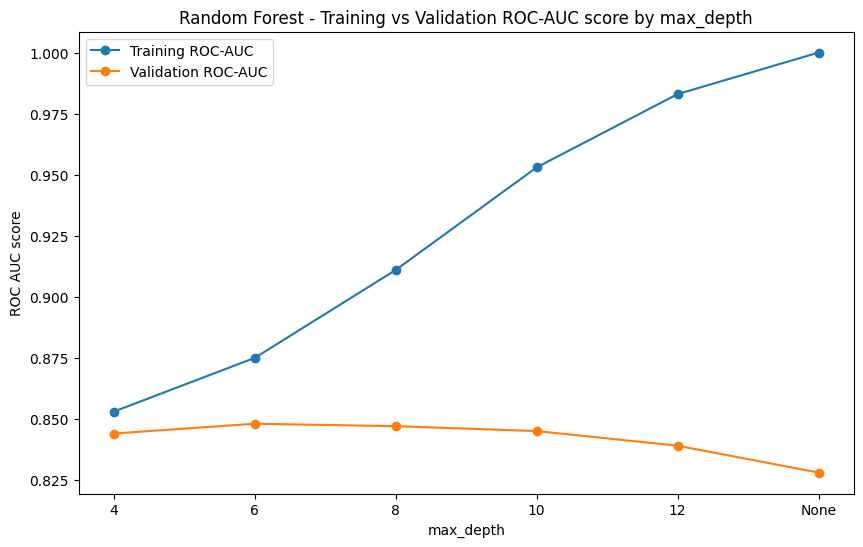

In [ ]:
#plot performance of the random forest at different max_depth
plt.figure(figsize=(10,6))
plt.plot(rf_depth_df['max_depth'], rf_depth_df['Training ROC-AUC score'], label='Training ROC-AUC', marker='o')
plt.plot(rf_depth_df['max_depth'], rf_depth_df['Validation ROC-AUC score'], label='Validation ROC-AUC', marker='o')
plt.title('Random Forest - Training vs Validation ROC-AUC score by max_depth')
plt.xlabel('max_depth')
plt.ylabel('ROC AUC score')
plt.legend()
plt.show()

Since Random Forest is made up of many decision trees, different maximum depths were tested using 5-fold cross-validation, comparing the training and validation ROC-AUC scores. From the test, we see that as the trees get deeper, the training score keeps increasing until it reaches a perfect score of 1 when there is no depth limit. The validation score peaked at a max_depth of 6 (0.848) and then slowly decreased the deeper the trees got. The widening gap between the training and validation ROC-AUC scores is a sign of overfitting. However, the decrease in the validation score is much smaller compared to the Decision Tree model (Random Forest fell to a lowest score of 0.828 with no depth limit compared with 0.663 in the Decision Tree model), since Random Forest averages the predictions of many trees, thus reducing overfitting. A maximum depth of 4 was selected because its validation ROC-AUC (0.844) was within 0.005 of the best score (0.848 at depth 6), which is consistent with our preference for the simpler model applied to the Decision Tree, and because it showed a much smaller gap between training and validation scores (0.009 compared with 0.027). Compared to the other models, the best random forest (validation ROC-AUC of 0.848) performed better than the Decision Tree (0.825), thus showing the benefits of using many trees instead on one tree. The random forest model performed slightly better than the logistic regression model (0.846) with the difference (0.002) being very small, thus suggesting that the two models performed equally well on this dataset.

In [ ]:
#create final random forest using maximum depth of 4
rf_model = RandomForestClassifier(n_estimators=300, max_depth=4, random_state=RANDOM_SEED, class_weight='balanced', n_jobs=-1)

#run 5-fold cross-validation on the Training set
rf_cv = cross_validate(rf_model, X_train, y_train, cv=cv, scoring=scoring)

#store results in the cv_results dictionary
cv_results['Random Forest'] = rf_cv

#fit the random forest model on the train set
rf_model.fit(X_train, y_train)

#display the mean and standard deviation of each metric across the 5 folds
print('Random Forest: 5-fold cross-validation (training set) results')
for metric in scoring:
    scores = rf_cv['test_' + metric]
    print(f'{metric:10}: mean = {scores.mean():.3f}, std = {scores.std():.3f}')

Random Forest: 5-fold cross-validation (training set) results
accuracy  : mean = 0.740, std = 0.011
precision : mean = 0.506, std = 0.013
recall    : mean = 0.819, std = 0.020
f1        : mean = 0.626, std = 0.013
roc_auc   : mean = 0.844, std = 0.010


A Random Forest with a max_depth = 4 was evaluated using 5-fold stratified cross-validation on the training set. The Random Forest model scored a ROC-AUC of 0.844, which shows that the model does well in separating churners from non-churners. The Random Forest model achieved a recall of 0.819, meaning the model correctly identified about 82% of customers who actually churned, while the model had a precision of 0.506, meaning that of the customers flagged as likely to churn, about half actually churned. The relationship of high recall and moderate precision is again the result of class weighting, which we used as a way of handling the class imbalance in the dataset. The F1 score (0.626) reflects the balance between precision and recall. Due to the class imbalance between churners and non-churners, accuracy (0.740) is less informative, since a model that simply predicted the majority class (not churning) would be right most of the time. The standard deviations were very low (all at or below 0.020), showing that performance was more consistent across folds than for both earlier models. Compared with the Decision Tree, the Random Forest performed better on every metric (ROC-AUC 0.844 vs 0.825; recall 0.819 vs 0.767). Compared with Logistic Regression, the Random Forest achieved the highest recall so far (0.819 vs 0.801), but its ROC-AUC was almost identical (0.844 vs 0.846) and its precision slightly lower (0.506 vs 0.518), so the two models perform equally well overall.

In [ ]:
#feature importance - calculate how much each feature contributed to the random forest trees
rf_feature_importance = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

#display the top important features
print('Random Forest - Top 10 features by importance:')
print(rf_feature_importance.head(10).round(3))

#number of features the random forest used to make its splits
print('\nNumber of features used by the random forest: ', (rf_feature_importance >0).sum(), 'out of ', len(rf_feature_importance))

Random Forest - Top 10 features by importance:
Contract_Month-to-month           0.265
Contract_Two year                 0.124
tenure                            0.122
InternetService_Fiber optic       0.111
MonthlyCharges                    0.067
TotalCharges                      0.066
PaymentMethod_Electronic check    0.065
InternetService_No                0.052
Contract_One year                 0.034
InternetService_DSL               0.017
dtype: float64

Number of features used by the random forest:  26 out of  26


Feature importance helped show how much each feature contributed to the splits across all the trees in the random forest (values add up to 1). From our features, we see that Contract_Month-to-month is the most important feature with a score of 0.265, followed by Contract_Two year (0.124), tenure (0.122) and InternetService_Fiber optic (0.111), with the top four features contributing about 62% of total importance in the Random Forest model. Unlike the Decision Tree model, the importance is spread more evenly across features, with MonthlyCharges, TotalCharges, electronic check payments and having no internet service each contributing between 0.05 and 0.07. Overall, the model used all 26 features, since each tree in the forest is built on a random selection of features, so most features end up being used by at least some of the trees in the forest. Overall, the most important features are consistent with the results of  Decision Tree and Logistic Regression, with contract type, tenure and fiber optic internet emerging as key drivers of customer churn.

# XGBoost

In [ ]:
#import XGBoost library
from xgboost import XGBClassifier

#scale class weight to handle class imbalance
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight: {scale_weight:.2f}')

#set the tree depths to test
xgb_depth_values = [1, 2, 3, 4, 5, 6]

#create variable where we will store the results of each depth
xgb_depth_rows = []

#create XGBoost (testing different depths)
for depth in xgb_depth_values:
    xgb_model = XGBClassifier(n_estimators=300, max_depth=depth, learning_rate=0.05, random_state=RANDOM_SEED, scale_pos_weight=scale_weight, n_jobs=-1, eval_metric='logloss')

    #run 5-fold cross-validation on the Training set
    xgb_cv = cross_validate(xgb_model, X_train, y_train, cv=cv, scoring='roc_auc', return_train_score=True)

    #store results in the xgb_depth_rows
    xgb_depth_rows.append({'max_depth': str(depth), 'Training ROC-AUC score': xgb_cv['train_score'].mean(), 'Validation ROC-AUC score': xgb_cv['test_score'].mean()})

#convert xgb_depth_rows into a dataframe
xgb_depth_df = pd.DataFrame(xgb_depth_rows)

#add column which gets the gap between the training and validation
xgb_depth_df['ROC-AUC Gap'] = xgb_depth_df['Training ROC-AUC score'] - xgb_depth_df['Validation ROC-AUC score']

#round values to three decimals
xgb_depth_df = xgb_depth_df.round(3)

#display results
xgb_depth_df

scale_pos_weight: 2.77


,max_depth,Training ROC-AUC score,Validation ROC-AUC score,ROC-AUC Gap
0,1,0.853,0.848,0.005
1,2,0.868,0.848,0.020
2,3,0.889,0.845,0.043
3,4,0.916,0.843,0.073
4,5,0.944,0.839,0.105
5,6,0.969,0.835,0.134


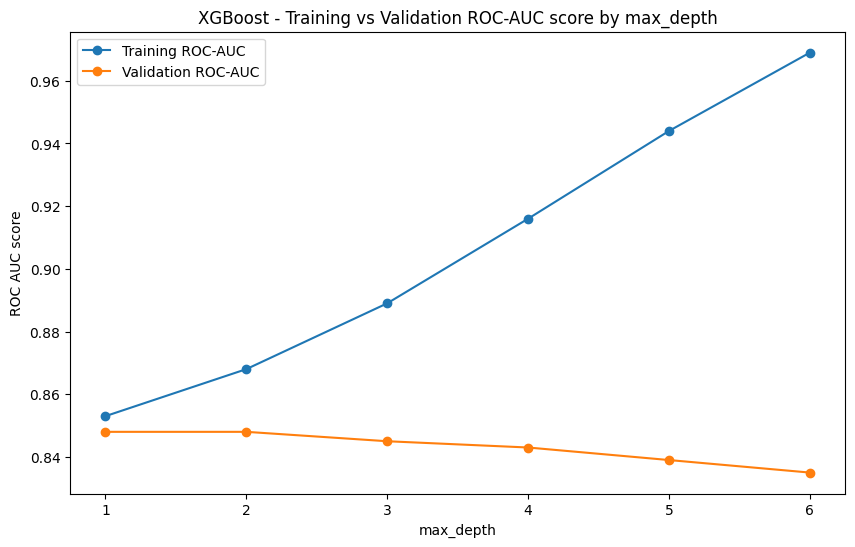

In [ ]:
#plot performance of the XGBoost at different max_depth
plt.figure(figsize=(10,6))
plt.plot(xgb_depth_df['max_depth'], xgb_depth_df['Training ROC-AUC score'], label='Training ROC-AUC', marker='o')
plt.plot(xgb_depth_df['max_depth'], xgb_depth_df['Validation ROC-AUC score'], label='Validation ROC-AUC', marker='o')
plt.title('XGBoost - Training vs Validation ROC-AUC score by max_depth')
plt.xlabel('max_depth')
plt.ylabel('ROC AUC score')
plt.legend()
plt.show()

Since XGBoost builds many trees one after another, with each new tree correcting the errors of the previous ones, it can easily overfit, so different maximum depths were tested using 5-fold cross-validation, comparing the training and validation ROC-AUC scores. To handle the class imbalance, scale_pos_weight was set to 2.77 (the number of non-churners for every churner in the training set), which gives churners more weight in the same way as class weighting in the earlier models. From the test, we see that as the trees get deeper, the training score keeps increasing, from 0.853 at depth 1 to 0.969 at depth 6. The validation score, however, was highest at the shallowest depths of 1 and 2 (both 0.848) and steadily decreased as the trees got deeper, falling to 0.835 at depth 6. The widening gap between the training and validation ROC-AUC scores (from 0.005 at depth 1 to 0.134 at depth 6) is a sign of overfitting. Following the same rule applied to the other models (highest validation ROC-AUC, preferring the shallower depth if within 0.005), a maximum depth of 1 was selected, as it matched the best validation score and had the smallest gap of all depths tested. Compared to the other models, XGBoost (validation ROC-AUC of 0.848) performed better than the Decision Tree (0.825) and achieved the highest validation score of all the models, slightly ahead of Logistic Regression (0.846) and the selected Random Forest (0.844). However, the differences between these three models are very small (0.004 or less), suggesting that XGBoost, Logistic Regression and Random Forest perform about equally well on this dataset.

In [ ]:
#create final XGBoost using maximum depth of 1
xgb_model = XGBClassifier(n_estimators=300, max_depth=1, learning_rate=0.05, random_state=RANDOM_SEED, scale_pos_weight=scale_weight, n_jobs=-1, eval_metric='logloss')

#run 5-fold cross-validation on the Training set
xgb_cv = cross_validate(xgb_model, X_train, y_train, cv=cv, scoring=scoring)

#store results in the cv_results dictionary
cv_results['XGBoost'] = xgb_cv

#fit the XGBoost model on the train set
xgb_model.fit(X_train, y_train)

#display the mean and standard deviation of each metric across the 5 folds
print('XGBoost: 5-fold cross-validation (training set) results')
for metric in scoring:
    scores = xgb_cv['test_' + metric]
    print(f'{metric:10}: mean = {scores.mean():.3f}, std = {scores.std():.3f}')

XGBoost: 5-fold cross-validation (training set) results
accuracy  : mean = 0.742, std = 0.013
precision : mean = 0.509, std = 0.016
recall    : mean = 0.824, std = 0.016
f1        : mean = 0.629, std = 0.016
roc_auc   : mean = 0.848, std = 0.012


An XGBoost model with a max_depth = 1 was evaluated using 5-fold stratified cross-validation on the training set. The XGBoost model scored a ROC-AUC of 0.848, which shows that the model does well in separating churners from non-churners. The XGBoost model achieved a recall of 0.824, meaning the model correctly identified about 82% of customers who actually churned, while the model had a precision of 0.509, meaning that of the customers flagged as likely to churn, about half actually churned. The relationship of high recall and moderate precision is again the result of class weighting (through scale_pos_weight), which we used as a way of handling the class imbalance in the dataset. The F1 score (0.629) reflects the balance between precision and recall. Due to the class imbalance between churners and non-churners, accuracy (0.742) is less informative, since a model that simply predicted the majority class (not churning) would be right most of the time. The standard deviations were very low (all at or below 0.016), similar to Random Forest, showing that performance was highly consistent across folds.Compared with the Decision Tree, XGBoost performed better on every metric (ROC-AUC 0.848 vs 0.825; recall 0.824 vs 0.767). Compared with the Random Forest, XGBoost performed slightly better on every metric (ROC-AUC 0.848 vs 0.844; recall 0.824 vs 0.819). Compared with Logistic Regression, XGBoost achieved the highest ROC-AUC (0.848 vs 0.846) and the highest recall of all the models (0.824 vs 0.801), with the same F1 score (0.629), but its precision was slightly lower (0.509 vs 0.518). Overall, XGBoost, Logistic Regression and Random Forest perform about equally well, with XGBoost holding a very small advantage.

In [ ]:
#feature importance - calculate how much each feature contributed to the XGBoost
xgb_feature_importance = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

#display the top important features
print('XGBoost - Top 10 features by importance:')
print(xgb_feature_importance.head(10).round(3))

#number of features the XGBoost
print('\nNumber of features used by the XGBoost: ', (xgb_feature_importance >0).sum(), 'out of ', len(xgb_feature_importance))

XGBoost - Top 10 features by importance:
Contract_Month-to-month           0.515
InternetService_Fiber optic       0.127
PaymentMethod_Electronic check    0.098
Contract_Two year                 0.085
InternetService_No                0.042
tenure                            0.030
PaperlessBilling                  0.024
OnlineSecurity                    0.017
StreamingMovies                   0.012
StreamingTV                       0.010
dtype: float32

Number of features used by the XGBoost:  17 out of  26


Feature importance helped show how much each feature contributed to the XGBoost model (values add up to 1). From our features, we see that Contract_Month-to-month is the most important feature with a score of 0.515, followed by InternetService_Fiber optic (0.127), PaymentMethod_Electronic check (0.098) and Contract_Two year (0.085), with the top four features contributing about 83% of total importance. The remaining features contributed very little, each scoring below 0.05. Overall, the model used 17 of the 26 features, suggesting that it relies mainly on a small number of features. Interestingly, tenure ranks much lower here (0.030) than in the Decision Tree and Random Forest. Overall, the most important features are consistent with the earlier models, with contract type and fiber optic internet emerging as key drivers of churn, with electronic check payments also standing out in the XGBoost model.

# Comparison of the four models for churn prediction

In [ ]:
#cross validation comparison table
#create empty list which will store each model's results as a single row
comparison_rows = []

#loop through each model's cross validation results
for model_name, results in cv_results.items():
  row = {'Model': model_name}
  #for each metric, return average score as well as standard deviation
  for metric in scoring:
    scores = results['test_' + metric]
    row[metric] = f'{scores.mean():.3f} ± {scores.std():.3f}'

  #append the rows to the list
  comparison_rows.append(row)

#convert the list into a table
cv_comparison = pd.DataFrame(comparison_rows).set_index('Model')

#display comparison table
cv_comparison

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Logistic Regression,0.749 ± 0.015,0.518 ± 0.019,0.801 ± 0.037,0.629 ± 0.023,0.846 ± 0.012
Decision Tree,0.738 ± 0.030,0.509 ± 0.041,0.767 ± 0.051,0.609 ± 0.020,0.825 ± 0.009
Random Forest,0.740 ± 0.011,0.506 ± 0.013,0.819 ± 0.020,0.626 ± 0.013,0.844 ± 0.010
XGBoost,0.742 ± 0.013,0.509 ± 0.016,0.824 ± 0.016,0.629 ± 0.016,0.848 ± 0.012


The table shows the average cross-validation score (± standard deviation) for each model. XGBoost performed best overall, with the highest ROC-AUC (0.848) and recall (0.824), meaning it was best at separating churners from non-churners and caught the most churners in the dataset. Logistic Regression came in second, with the highest precision (0.518) and accuracy (0.749), and the same F1 score as XGBoost (0.629). Random Forest came in third, while the Decision Tree performed lowest on almost every metric. It is important to note that the differences between XGBoost, Logistic Regression and Random Forest are very small, so these three models perform about equally well.

In [ ]:
#the four final models (cross_validate makes fresh copies, so earlier fitting does not matter)
final_models = {'Logistic Regression': log_reg_pipeline,'Decision Tree': decision_tree_model,'Random Forest': rf_model,'XGBoost': xgb_model}

#training features without TotalCharges
X_train_no_tc = X_train.drop(columns='TotalCharges')

sensitivity_rows = []

for model_name, model in final_models.items():
    #cross-validated ROC-AUC with all features
    with_tc = cross_validate(model, X_train, y_train, cv=cv, scoring='roc_auc')

    #cross-validated ROC-AUC without TotalCharges
    without_tc = cross_validate(model, X_train_no_tc, y_train, cv=cv, scoring='roc_auc')

    sensitivity_rows.append({
        'Model': model_name,
        'ROC-AUC with TotalCharges': with_tc['test_score'].mean(),
        'ROC-AUC without TotalCharges': without_tc['test_score'].mean()})

#results table with the change in ROC-AUC
sensitivity_df = pd.DataFrame(sensitivity_rows).set_index('Model')
sensitivity_df['Change'] = sensitivity_df['ROC-AUC without TotalCharges'] - sensitivity_df['ROC-AUC with TotalCharges']
sensitivity_df = sensitivity_df.round(4)
sensitivity_df

,ROC-AUC with TotalCharges,ROC-AUC without TotalCharges,Change
Model,,,
Logistic Regression,0.8460,0.8448,-0.0012
Decision Tree,0.8252,0.8254,0.0002
Random Forest,0.8440,0.8421,-0.0019
XGBoost,0.8481,0.8479,-0.0002


A TotalCharges sensitivity check was done since TotalCharges is strongly correlated with tenure (correlation  = 0.83) and caused misleading coefficients in the Logistic Regression model, each model was re-tested without it. Removing TotalCharges changed the cross-validated ROC-AUC by less than 0.002 for every model, with the largest change in ROC AUC being -0019 from the Random Forest model. Since all changes were well within the pre-set limit of 0.005, TotalCharges will be removed from all models.

In [ ]:
#remove TotalCharges from the training and test sets
X_train = X_train.drop(columns='TotalCharges')
X_test = X_test.drop(columns='TotalCharges')

#confirm if Total Charges has been dropped, new shape should have 25 features
print(f'Shape of the training set: {X_train.shape}')
print(f'Shape of the testing set: {X_test.shape}')

Shape of the training set: (5634, 25)
Shape of the testing set: (1409, 25)


In [ ]:
#re-run cross-validation and refit all four models
cv_results = {}

for model_name, model in final_models.items():
    cv_results[model_name] = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)

    #refit the model
    model.fit(X_train, y_train)
    print(f'{model_name}: done')

Logistic Regression: done
Decision Tree: done
Random Forest: done
XGBoost: done


In [ ]:
#Updated comparison table (after removing TotalCharges)
#create empty list which will store each model's results as a single row
comparison_rows = []

#loop through each model's cross validation results
for model_name, results in cv_results.items():
  row = {'Model': model_name}
  #for each metric, return average score as well as standard deviation
  for metric in scoring:
    scores = results['test_' + metric]
    row[metric] = f'{scores.mean():.3f} ± {scores.std():.3f}'

  #append the rows to the list
  comparison_rows.append(row)

#convert the list into a table
cv_comparison = pd.DataFrame(comparison_rows).set_index('Model')

#display comparison table
cv_comparison

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Logistic Regression,0.750 ± 0.014,0.519 ± 0.018,0.793 ± 0.033,0.627 ± 0.021,0.845 ± 0.012
Decision Tree,0.738 ± 0.030,0.509 ± 0.041,0.767 ± 0.051,0.609 ± 0.020,0.825 ± 0.008
Random Forest,0.738 ± 0.010,0.504 ± 0.012,0.811 ± 0.023,0.621 ± 0.013,0.842 ± 0.009
XGBoost,0.742 ± 0.013,0.508 ± 0.016,0.821 ± 0.014,0.628 ± 0.015,0.848 ± 0.012


On cross-validated ROC-AUC, XGBoost (0.848) and Logistic Regression (0.845) were practically tied (within 0.005 threshold), with Random Forest (0.842) and the Decision Tree (0.825) lower. On the secondary criteria (recall), XGBoost achieved higher recall than logistic Regression (0.821 vs 0.793) with equivalent F1 (0.628 vs 0.627). XGBoost was therefore selected for SHAP analysis.

In [ ]:
#re-inspect the Logistic Regression coefficients after removing TotalCharges
updated_coefficients = pd.Series(
    log_reg_pipeline.named_steps['logisticregression'].coef_[0],
    index=X_train.columns
).sort_values()

print('Most negative coefficients:')
print(updated_coefficients.head(6).round(3))
print('\nMost positive coefficients:')
print(updated_coefficients.tail(6).round(3))

Most negative coefficients:
MonthlyCharges       -0.861
tenure               -0.754
InternetService_No   -0.725
Contract_Two year    -0.339
OnlineSecurity       -0.111
Dependents           -0.110
dtype: float64

Most positive coefficients:
PaperlessBilling               0.164
MultipleLines                  0.209
StreamingTV                    0.277
StreamingMovies                0.289
Contract_Month-to-month        0.321
InternetService_Fiber optic    0.697
dtype: float64


After TotalCharges was removed, the Logistic Regression coefficients were re-inspected. The main drivers stayed the same: fiber optic internet (0.697) and month-to-month contracts (0.321) are still most linked to higher churn, while having no internet service (−0.725) and a two-year contract (−0.339) are still linked to lower churn. The biggest change is tenure, whose coefficient dropped from −1.153 to −0.754. This could be because tenure no longer has to balance out the opposite effect of TotalCharges, so its value is now more realistic. However, MonthlyCharges is still negative (−0.861), which suggest that higher charges reduce churn. This is unlikely to be true, since MonthlyCharges is mainly determined by the add-on services a customer is subscribed to, such as fiber and streaming services. Because MonthlyCharges is heavily influenced by other features, its individual coefficient can't be trusted on it's own.

# Final evaluation on the test set

In [ ]:
#import libraries for model evaluation
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve,RocCurveDisplay, accuracy_score, precision_score, recall_score, f1_score

#create empty dictionaries which will store the predictions and probabilities of each model
test_predictions = {}
test_probabilities = {}

#create empty list which will store each model's results as a single row
test_rows = []

#loop through each model
for model_name, model in final_models.items():
    #make predictions on the test and save the predictions
    y_pred = model.predict(X_test)
    test_predictions[model_name] = y_pred

    #make probabilities on the test and save the probabilities
    y_proba = model.predict_proba(X_test)[:, 1]
    test_probabilities[model_name] = y_proba

    #compare predictions (y_pred) with the actual answers (y_test)
    test_rows.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

#convert the list into a table
test_results_df = pd.DataFrame(test_rows).set_index('Model').round(3)

#display results
test_results_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.740,0.507,0.775,0.613,0.838
Decision Tree,0.751,0.521,0.778,0.624,0.836
Random Forest,0.732,0.498,0.799,0.613,0.834
XGBoost,0.733,0.498,0.816,0.619,0.843


The four models were evaluated on the test set, with the test scores close to the cross-validation scores, showing that the models were not overfitting and generalise well to new customers. XGBoost performed best overall, having the highest ROC-AUC (0.843) and recall (0.816), meaning that it was the best at separating churners from non-churners and caught about 82% of customers who actually churned. However, the Decision Tree, which was the weakest model in cross-validation, achieved the highest test accuracy (0.751), precision (0.521) and F1 score (0.624). This could be because the Decision Tree showed the greatest variability during cross-validation, so its performance on a single test set can land at the higher end of its range by chance. Overall, the ROC-AUC scores ranged between 0.834 and 0.843, indicating that all four models performed quite similarly in predicting customer churn, with XGBoost selected as the best model.

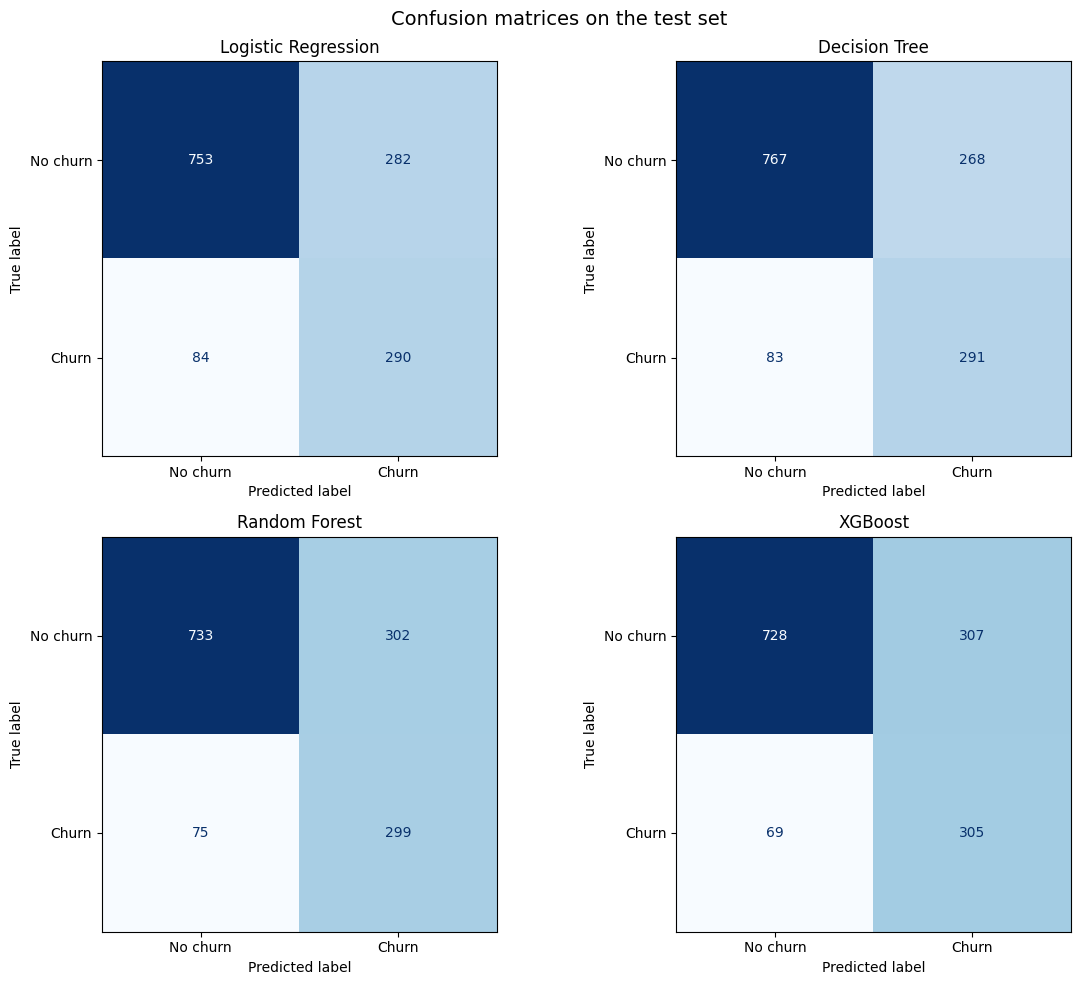

In [ ]:
#create a 2x2 grid of charts and turn it into a simple list of 4 boxes
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

#loop through each model and its matching box in the grid
for ax, (model_name, y_pred) in zip(axes, test_predictions.items()):
    #calculate and draw the confusion matrix in one step
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No churn', 'Churn'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(model_name)  #label each chart with its model name

#add an overall title, stop the charts overlapping, save and display
plt.suptitle('Confusion matrices on the test set', fontsize=14)
plt.tight_layout()
plt.savefig('fig_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

* Logistic Regression correctly caught 290 of the 374 customers who churned and missed 84. It also correctly identified 753 customers who did not churn but raised 282 false alarms (predicted that they churned but they actually stayed).

* Decision Tree correctly caught 291 of the 374 customers who churned and missed 83, almost the same as the Logistic Regression model. Decision tree had the fewest false alarms (268) and the most correct "stay" predictions (767), which explains why it had a slightly higher accuracy and precision.

* Random Forest correctly caught 299 of the 374 customers who churned and missed only 75, doing better than the first two models at finding churners. However, this came at the cost of more false alarms (302).

* XGBoost correctly caught the most churners (305) and missed the fewest (69), making it the best model for finding customers who are about to leave the company. It also had the most false alarms (307), which illustrates the trade-off between catching more churners and wrongly flagging more loyal customers as likely to churn.

<BR>

Overall, XGBoost correctly caught the most churners. For a customer churn problem such as the one we are dealing with, this is usually the priority, as missing a customer who leaves is more costly than contacting one who would have stayed.


The confusion matrices in Figure 4.6 show the trade-off between identifying churners and raising false alarms. Logistic Regression correctly identified 290 of the 374 churners and missed 84, while raising 282 false alarms (i.e. customers predicted to churn who actually stayed). The Decision Tree identified a similar number of churners (291) and missed 83, but raised the fewest false alarms (268) and correctly identified the most customers who stayed (767), which explains its higher accuracy and precision. Random Forest identified 299 churners and missed 75, but raised more false alarms (302). XGBoost identified the most churners (305) and missed the fewest (69), but also raised the most false alarms (307). Compared with Logistic Regression, XGBoost identified 15 more churners at the cost of 25 more false alarms. The ROC curves in Figure 4.7 show that all four models performed well above random guessing, and their curves almost completely overlap.

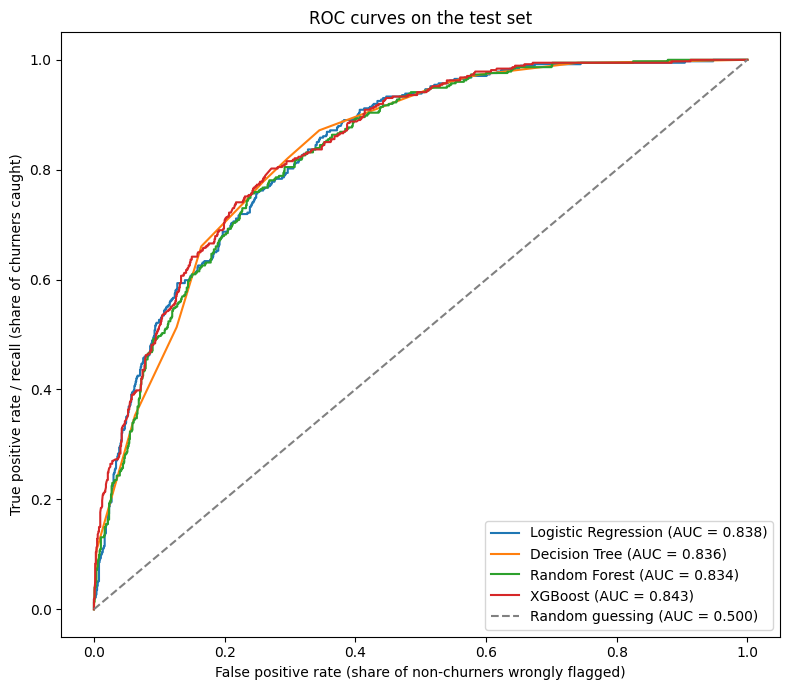

In [ ]:
#display roc curve for all models
plt.figure(figsize=(8, 7))

for model_name, y_prob in test_probabilities.items():
    #false positive rate and true positive rate at every possible threshold
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc:.3f})')

#diagonal line = a model that guesses randomly (AUC = 0.5)
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random guessing (AUC = 0.500)')

plt.title('ROC curves on the test set')
plt.xlabel('False positive rate (share of non-churners wrongly flagged)')
plt.ylabel('True positive rate / recall (share of churners caught)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('fig_roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

The ROC curve was used to show how well each model separates churners from non-churners. From the chart, we see that all four models sit well above the grey dashed line (random guessing), showing that they are much better than random chance. We also see that the curves almost completely overlap one another, thus confirming that the models perform quite similarly, with the AUC scores ranging from 0.834 (Random Forest) to 0.843 (XGBoost), confirming XGBoost as the best overall model, though by a small margin.

# **Explainable AI**

In [ ]:
#calculate SHAP values for XGBoost model
explainer = shap.TreeExplainer(xgb_model)

#calculate SHAP values for each of the customers in the test set
shap_values = explainer.shap_values(X_test)

#Check the size of SHAP values
print(f'SHAP values shape: {shap_values.shape}')

#get the base value directly from the explainer
base_log_odds = explainer.expected_value
base_probability = 1 / (1 + np.exp(-base_log_odds))
print(f'Base value: {base_log_odds:.3f} log-odds (= {base_probability:.1%} probability)')

SHAP values shape: (1409, 25)
Base value: -0.001 log-odds (= 50.0% probability)


SHAP values were calculated for the XGBoost model using TreeExplainer, with a SHAP value produced for each of the 1409 customers in the test and each of the 25 features. The base value (model’s starting prediction before considering features) was −0.001 log-odds, which was equal to approximately 50% customer churn probability. This probability is higher than the actual churn rate (26.5%) because we used “scale_pos_weight”, which helped balance the importance of churners and non-churners.

In [ ]:
#for each customer - calculate the base value + sum of SHAP values
shap_totals = base_log_odds + shap_values.sum(axis=1)

#the model's own prediction in log-odds
model_log_odds = xgb_model.predict(X_test, output_margin=True)

#check whether the SHAP totals match the model's predictions for every customer
print('Additivity holds for all customers:', np.allclose(shap_totals, model_log_odds, atol=1e-4))

#show the biggest difference between SHAP totals and the model's predictions
print('Largest difference:', np.abs(shap_totals - model_log_odds).max())

Additivity holds for all customers: True
Largest difference: 2.861023e-06


SHAP additivity check was performed, with the check confirming that additivity holds for all the customers, meaning that the base value plus the SHAP values of the features add up exactly to the model's predictions. The largest difference between SHAP totals and the model’s predictions was 0.0000029 (which is very small), thus confirming that SHAP values are able to fully account for every prediction made by the XGBoost model.

# XAI - global explanations

In [ ]:
#get global explanations - which features matter the most overall to the XGBoost model's predictions using SHAP
#put the SHAP values in a table - one row per test customer
shap_df = pd.DataFrame(shap_values, columns=X_test.columns, index=X_test.index)

#get the mean absolute SHAP value for each feature
mean_abs_shap = shap_df.abs().mean().sort_values(ascending=False)

print('Mean absolute SHAP values for each feature:')
print(mean_abs_shap.round(3))

Mean absolute SHAP values for each feature:
Contract_Month-to-month                    0.541
tenure                                     0.513
InternetService_Fiber optic                0.396
InternetService_No                         0.205
Contract_Two year                          0.190
PaymentMethod_Electronic check             0.164
PaperlessBilling                           0.122
StreamingMovies                            0.095
OnlineSecurity                             0.094
StreamingTV                                0.084
TechSupport                                0.044
MonthlyCharges                             0.044
Dependents                                 0.035
MultipleLines                              0.025
SeniorCitizen                              0.017
PhoneService                               0.004
gender_Male                                0.000
OnlineBackup                               0.000
Partner                                    0.000
InternetService_DSL      

Mean absolute SHAP values were used to show how much each feature affected the model’s churn predictions on average, regardless of the direction (i.e. Positive/Negative). From the features we see that Contract_Month-to-month (0.541) and tenure (0.513) had the largest effect, followed by InternetService_Fiber optic (0.396). Several features, such as PaymentMethod_Bank transfer (automatic), PaymentMethod_Credit card (automatic), and PaymentMethod_Mailed check, had SHAP values of 0, meaning the model never used them.

In [ ]:
#calculate how important each original variable is (joining the onehot columns back together)
#create a copy of the shap_df, so we keep the orginal shap_df
grouped_shap_df = shap_df.copy()

#find variables belonging to multicategory features
for variable in ['Contract', 'PaymentMethod', 'InternetService']:
    variable_columns = [column for column in shap_df.columns if column.startswith(variable + '_')]

    #add the columns together for each customer
    grouped_shap_df[variable] = shap_df[variable_columns].sum(axis=1)

    #remove the separate one-hot columns
    grouped_shap_df = grouped_shap_df.drop(columns=variable_columns)

#get the mean absolute SHAP value for each original feature
grouped_mean_abs_shap = grouped_shap_df.abs().mean().sort_values(ascending=False)

print('Mean absolute SHAP values for each original feature:')
print(grouped_mean_abs_shap.round(3))

Mean absolute SHAP values for each original feature:
Contract            0.696
InternetService     0.534
tenure              0.513
PaymentMethod       0.164
PaperlessBilling    0.122
StreamingMovies     0.095
OnlineSecurity      0.094
StreamingTV         0.084
TechSupport         0.044
MonthlyCharges      0.044
Dependents          0.035
MultipleLines       0.025
SeniorCitizen       0.017
PhoneService        0.004
gender_Male         0.000
DeviceProtection    0.000
Partner             0.000
OnlineBackup        0.000
dtype: float32


After combining the one-hot encoding columns back into their original variables, Contract becomes the most important variable (0.696), followed by InternetService (0.534) and tenure (0.513). Several features, such as OnlineBackup, Partner, and DeviceProtection had SHAP values of 0, meaning the model never used them.

/tmp/ipykernel_3269/436042304.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, plot_type='bar', show=False)


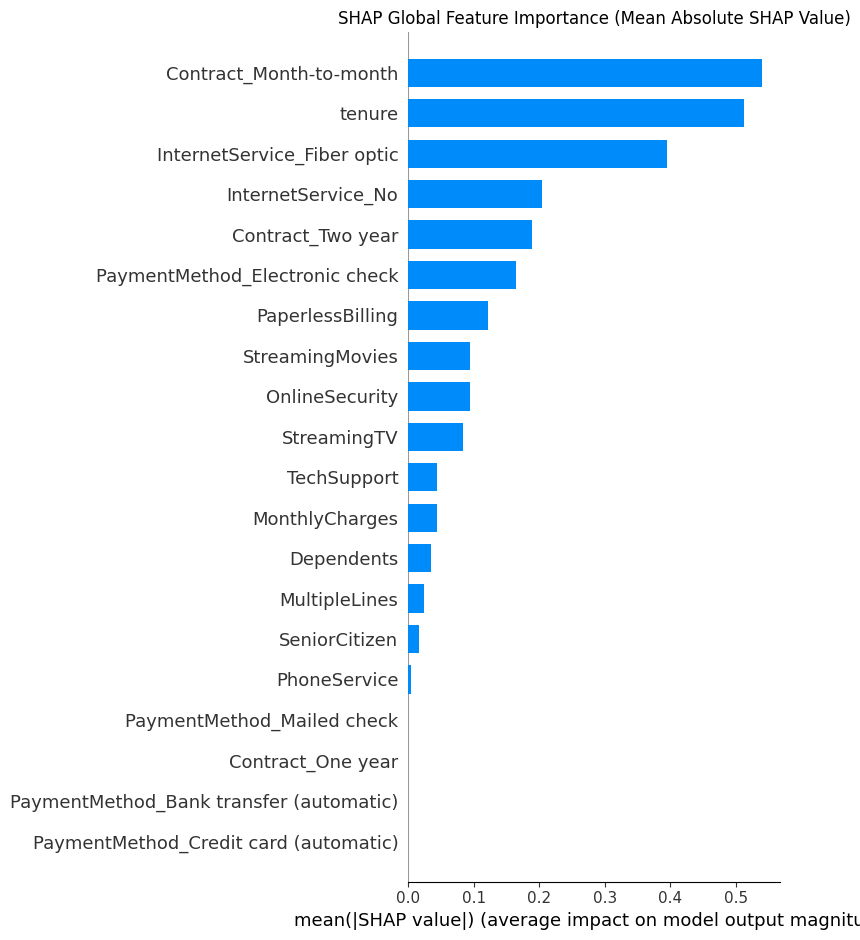

In [ ]:
#bar chart showing SHAP Values
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type='bar', show=False)
plt.title('SHAP Global Feature Importance (Mean Absolute SHAP Value)')
plt.tight_layout()
plt.savefig('fig_shap_global_importance.png', dpi=300, bbox_inches='tight')
plt.show()

The above bar chart shows the average impact of each feature on the model’s churn predictions. From the features we see that Contract_Month-to-month ,and tenure had the largest effect, followed by InternetService_Fiber optic. The bottom four features (PaymentMethod_Mailed check, Contract_One_Year, PaymentMethod_Bank transfer (automatic), and PaymentMethod_Credit card (automatic)) had no bar,  meaning the model never used them.

/tmp/ipykernel_3269/1736245127.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, show=False)


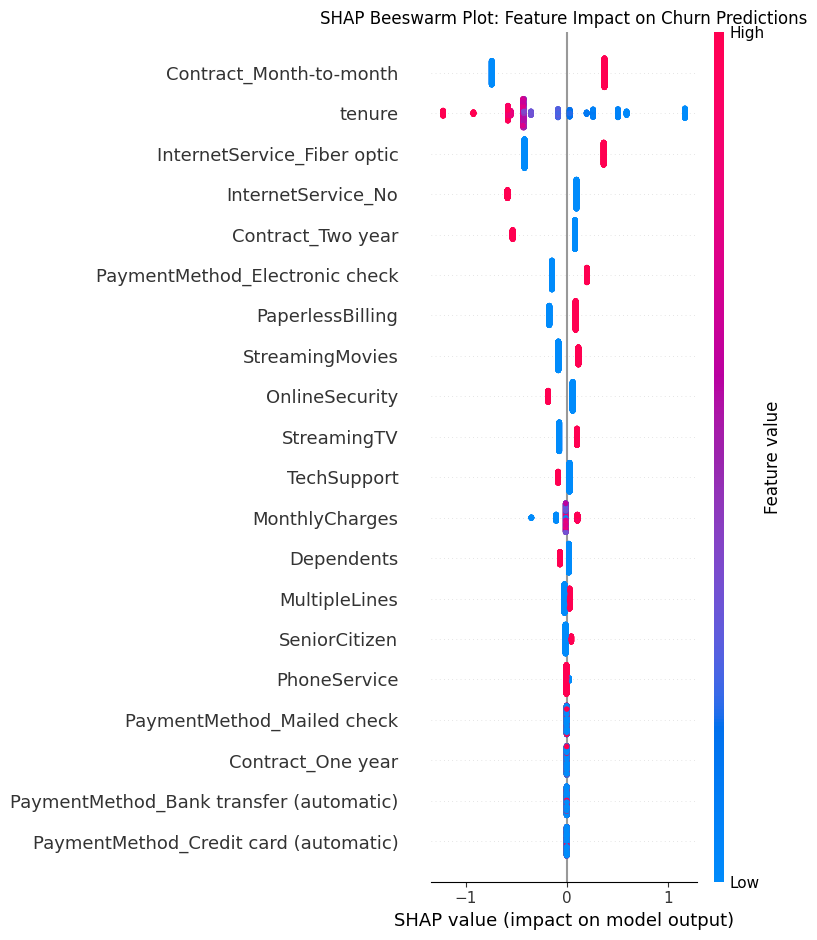

In [ ]:
#generate beeswarm plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, show=False)
plt.title('SHAP Beeswarm Plot: Feature Impact on Churn Predictions')
plt.tight_layout()
plt.savefig('fig_shap_beeswarm.png', dpi=300, bbox_inches='tight')
plt.show()

The beeswarm plot helps show how much and in what direction each feature affects the model’s churn predictions. From the beeswarm plot, the dots represent customers, with the dots on the right pushing customer churn up while the dots on the left are pushing customer churn down. Red dots show customers who have the feature (or a high value of it), and blue dots show customers who do not. The plot shows that customers on month-to-month contracts, with fiber optic internet, or paying by electronic check are more likely to churn. Additionally, we see that new customers (i.e. have a short tenure) are also more likely to churn, while long-standing customers are much less likely to churn. We also see that customers with a two-year contract, no internet service, online security or tech support are less likely to churn. Overall, the customers most at risk of churning are new customers, on month-to-month contracts and using fiber optic internet.

# XAI - local explanations

<BR>

Focus on three example customers from the test set:


1.   Customer with the highest predicted churn probability who actually churned
2.   A missed churner (false negative) (predicted "no churn", but they actually churned)
3.   Customer with a very low predicted churn probability who did not churn



In [ ]:
#combine the XGBoost test results into one table
xgb_results = pd.DataFrame({'actual': y_test, 'predicted': test_predictions['XGBoost'],'probability': test_probabilities['XGBoost']}, index=X_test.index)

#customer 1: customer with the highest predicted churn probability who actually churned
customer_1 = xgb_results[xgb_results['actual'] == 1]['probability'].idxmax()

#customer 2: most confidently missed churner (actually churned, predicted "no churn", lowest probability)
missed_churners = xgb_results[(xgb_results['actual'] == 1) & (xgb_results['predicted'] == 0)]
customer_2 = missed_churners['probability'].idxmin()

#customer 3: customer with the lowest predicted churn probability among customers who did not churn
customer_3 = xgb_results[xgb_results['actual'] == 0]['probability'].idxmin()

print('Selected customers index labels:')
print(f'Customer 1 index: {customer_1}')
print(f'Customer 2 index: {customer_2}')
print(f'Customer 3 index: {customer_3}')
print('\nNumber of missed churners (false negatives):', len(missed_churners))

Selected customers index labels:
Customer 1 index: 3380
Customer 2 index: 4513
Customer 3 index: 4201

Number of missed churners (false negatives): 69


The above code indicates the index in which our three chosen customers are found in the test set. We also checked the number of missed churners in the test set, which was 69.

In [ ]:
#original values from df_clean for the three customers
profile_columns = ['tenure', 'Contract', 'InternetService', 'MonthlyCharges', 'PaymentMethod',
                   'PaperlessBilling', 'OnlineSecurity', 'TechSupport', 'StreamingTV',
                   'StreamingMovies', 'SeniorCitizen', 'Partner', 'Dependents']

#store the three customers in a list
selected = [customer_1, customer_2, customer_3]

#lookup the three customers in df_clean
customer_profiles = df_clean.loc[selected, profile_columns].copy()

#include which segment each customer belongs to
customer_profiles['Segment'] = segment_df.loc[selected, 'segment_name']

#include whether each customer really churned
customer_profiles['Actually churned'] = xgb_results.loc[selected, 'actual'].map({1: 'Yes', 0: 'No'})

#likelihood our model thought each customer would churn
customer_profiles['Predicted churn probability'] = xgb_results.loc[selected, 'probability'].round(3)

#rename index
customer_profiles.index = ['Customer 1', 'Customer 2', 'Customer 3']
customer_profiles.T

,Customer 1,Customer 2,Customer 3
tenure,1,72,72
Contract,Month-to-month,Two year,Two year
InternetService,Fiber optic,DSL,No
MonthlyCharges,95.1,92.45,19.55
PaymentMethod,Electronic check,Credit card (automatic),Bank transfer (automatic)
PaperlessBilling,Yes,No,No
OnlineSecurity,No,Yes,No internet service
TechSupport,No,Yes,No internet service
StreamingTV,Yes,Yes,No internet service
StreamingMovies,Yes,Yes,No internet service


Above table provides a profile of the three selected customers. Customer 1, had been with the company for only 1 month, were on a month-to-month contract with fiber optic internet, paid by electronic check and had no online security or tech support. They belong to the Uncommitted High Spend Customers segment, with the model giving them a high churn probability of 94.1%. Customer 2 was the model’s biggest missed churner. The customer had been with the company for 72 months, were on a two-year contract, paid automatically and had security and tech support, all characteristics of a long-standing, contracted customer, hence the model only gave them a churn probability of 3.9%, even though the customer actually churned, possibly due to reasons not captured in the dataset. Importantly, customer 2 belonged to the Long-Standing Premium segment, which had a churn rate of 9.6%,  with the model learning that customers in this segment rarely churning. Customer 3 (long-standing, contracted customer) has been with the company for 72 months, on a two-year contract, no internet service and low monthly charges and they belong to the Long Standing Low Spend Customers segment, with the model predicting a very low churn probability (1.6%)

In [ ]:
#waterfall plot for the three customers
def explain_customer(customer_index, title, file_name):
    #bundle this customer's SHAP values and feature values into a SHAP Explanation object
    explanation = shap.Explanation(values=shap_df.loc[customer_index].values,base_values=base_log_odds,data=X_test.loc[customer_index].values,feature_names=X_test.columns.tolist())

    #waterfall plot showing the 10 most influential features for the customer
    shap.plots.waterfall(explanation, max_display=10, show=False)
    plt.title(title)
    plt.savefig(file_name, dpi=300, bbox_inches='tight')
    plt.show()

    #convert the final log-odds into a probability for easier interpretation
    final_log_odds = base_log_odds + shap_df.loc[customer_index].sum()
    print(f'Final prediction: {final_log_odds:.3f} log-odds = {1 / (1 + np.exp(-final_log_odds)):.1%} churn probability')

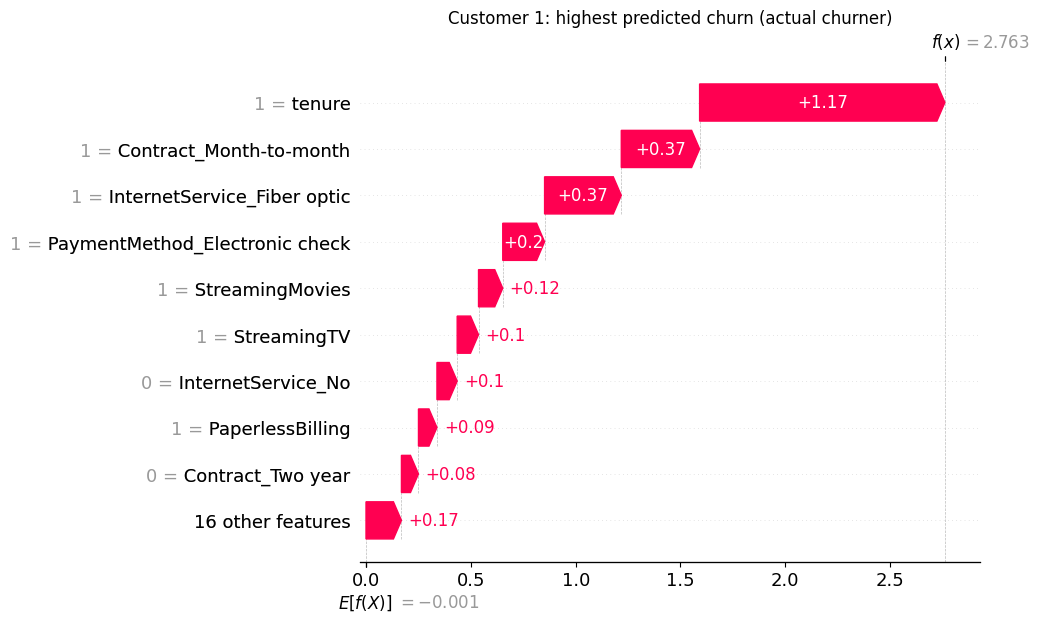

Final prediction: 2.763 log-odds = 94.1% churn probability


In [ ]:
#explain customer 1
explain_customer(customer_1, 'Customer 1: highest predicted churn (actual churner)', 'fig_shap_waterfall_customer1.png')

The above waterfall plot shows why the model predicted that Customer 1 would churn. The prediction starts at the base value of about 50%, and all displayed features pushed it towards churn (all red bars), ending at a 94.1% churn probability. The biggest pushes came from tenure (+1.17), since the customer had been with the company for only 1 month, followed by the month-to-month contract (+0.37), fiber optic internet (+0.37) and paying by electronic check (+0.20). Other features, such as streaming services and paperless billing, added smaller pushes. The model was able to make such a strong churn prediction because none of the features pulled the prediction down (no blue bars), and the prediction was correct, as this customer did indeed churn.

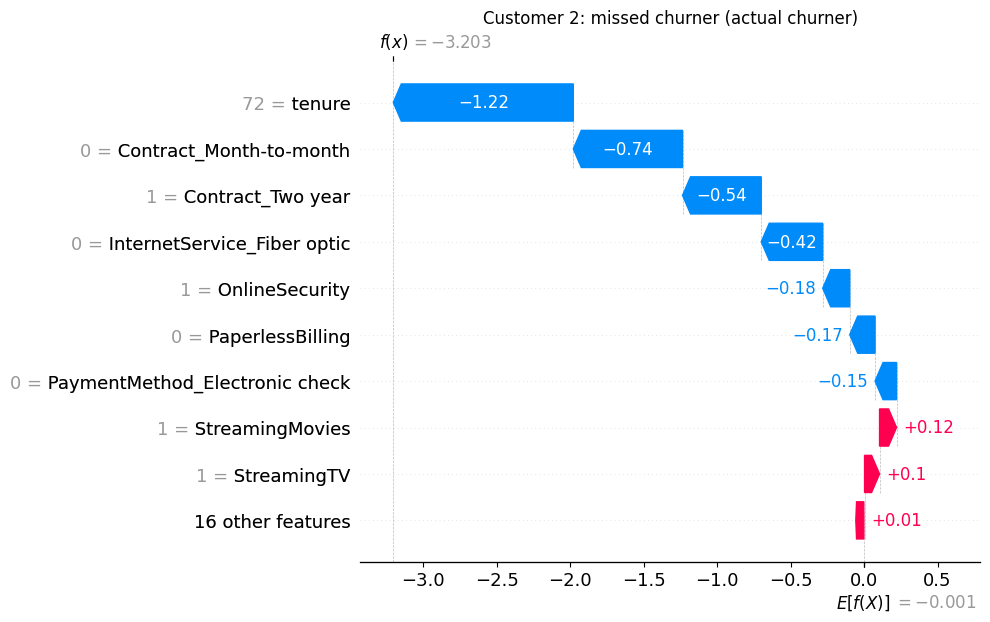

Final prediction: -3.203 log-odds = 3.9% churn probability


In [ ]:
#explain customer 2
explain_customer(customer_2, 'Customer 2: missed churner (actual churner)', 'fig_shap_waterfall_customer2.png')

The above waterfall plot shows why the model wrongly predicted that Customer 2 would stay. The prediction starts at the base value of about 50%, and almost every feature pulled it away from churn (blue bars), ending at a churn probability of only 3.9%. The biggest pulls came from tenure (−1.22), since the customer had been with the company for 72 months, followed by not being on a month-to-month contract (−0.74), having a two-year contract (−0.54) and not having fiber optic internet (−0.42). Other features, such as having online security and not using paperless billing, added smaller pulls. Only streaming movies and TV pushed slightly towards churn (red bars). The model missed this churner because every feature it relies on described a loyal customer, suggesting the customer churned (left) for reasons not captured in the data.

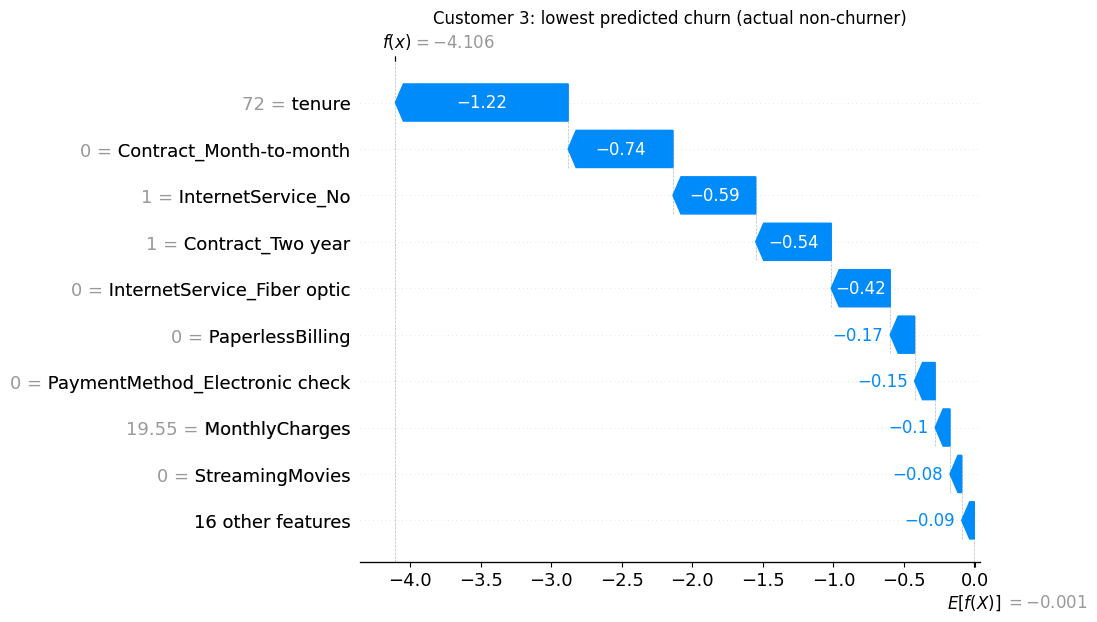

Final prediction: -4.106 log-odds = 1.6% churn probability


In [ ]:
#explain customer 3
explain_customer(customer_3, 'Customer 3: lowest predicted churn (actual non-churner)', 'fig_shap_waterfall_customer3.png')

The above waterfall plot shows why the model predicted that Customer 3 would stay. The prediction starts at the base value of about 50%, and every feature pulled it away from churn (all blue bars), ending at a churn probability of only 1.6%. The biggest pulls came from tenure (−1.22), since the customer had been with the company for 72 months, followed by not being on a month-to-month contract (−0.74), having no internet service (−0.59) and having a two-year contract (−0.54). Other features, such as low monthly charges (19.55) and not paying by electronic check, added smaller pulls. The model was able to make such a strong "no churn" prediction because none of the features pushed the prediction towards churn (no red bars), and the prediction was correct, as this customer did not churn.

In [ ]:
from PIL import Image

#open the three saved waterfall plots
files = ['fig_shap_waterfall_customer1.png',
         'fig_shap_waterfall_customer2.png',
         'fig_shap_waterfall_customer3.png']
images = [Image.open(file) for file in files]

#stack them vertically (one under the other) on a white background
width = max(image.width for image in images)
height = sum(image.height for image in images)
combined = Image.new('RGB', (width, height), 'white')

y_position = 0
for image in images:
    combined.paste(image, (0, y_position))
    y_position += image.height

combined.save('fig_shap_waterfall_combined.png')

# XAI - Segment Analysis

In [ ]:
#checks how well XGBoost works with the four segments
#get segment name for every customer in the test set
test_segments = segment_df.loc[X_test.index, 'segment_name']

#create empty list which will store one row for each segment
segment_performance_rows = []

for segment in name_order:
    #select the test customers belonging to this segment
    in_segment = test_segments == segment
    actual = xgb_results.loc[in_segment, 'actual']
    predicted = xgb_results.loc[in_segment, 'predicted']
    probability = xgb_results.loc[in_segment, 'probability']

    #calculate segment results and save them in a row
    segment_performance_rows.append({
        'Segment': segment,
        'Test customers': in_segment.sum(),
        'Churners': actual.sum(),
        'Actual churn rate (%)': actual.mean() * 100,
        'Mean predicted probability (%)': probability.mean() * 100,
        'Recall': recall_score(actual, predicted, zero_division=0),
        'Precision': precision_score(actual, predicted, zero_division=0),
        'Missed churners (FN)': ((actual == 1) & (predicted == 0)).sum(),
        'False alarms (FP)': ((actual == 0) & (predicted == 1)).sum()})

#convert the rows into a table and show the table
segment_performance = pd.DataFrame(segment_performance_rows).set_index('Segment').astype(float).round(2)
segment_performance

,Test customers,Churners,Actual churn rate (%),Mean predicted probability (%),Recall,Precision,Missed churners (FN),False alarms (FP)
Segment,,,,,,,,
Long-Standing Premium,303.0,29.0,9.57,20.38,0.10,0.33,26.0,6.0
New Low-Spend,333.0,101.0,30.33,45.99,0.75,0.48,25.0,82.0
Uncommitted High-Spend,541.0,241.0,44.55,66.48,0.94,0.51,15.0,219.0
Long-Standing Low-Spend,232.0,3.0,1.29,6.70,0.00,0.00,3.0,0.0


The above table shows how XGBoost performed across the four customer segments. For the Uncommitted High Spend Customers, the model performed very well, with the model catching 94% of churners (recall), and missing only 15 churners. 219 of the 307 false alarms (71%) fall in Uncommitted High-Spend Customers segment. For the New Low-Spend Customers, the model was able to catch 75% of churners, missing 25 churners, while it also had 82 false alarms. From the results, we see that the model struggles in the two long-standing segments. For Long Standing Premium Customers, the model was only able to catch 3 of the 29 churners, with 26 missed churners (hence recall of 0.10), while for Long Standing Low Spend Customers, the model missed all three churners (hence recall of 0.00). Overall, of the 69 missed churners, 29 came from the two long-standing segments. From the results, we see that the model does well in picking up churners in high-risk segments, but performs poorly in terms of spotting rare churners among long-standing customers, suggesting that perhaps for long-standing customers, retention strategies should not only oon the model.

**SHAP contributions by customer segment**

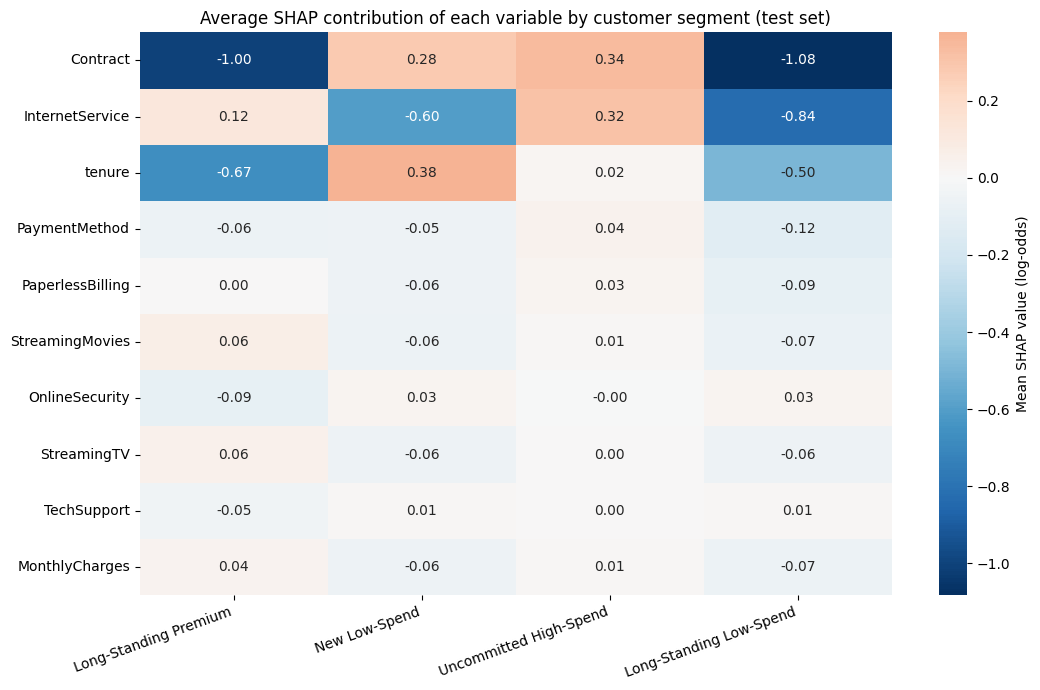

In [ ]:
#display which features push churn up or down within each of the four segments

#get average SHAP value of each variable for each segment
segment_shap = grouped_shap_df.groupby(test_segments).mean().T

#keep the columns in the usual segment order and the rows in global importance order
segment_shap = segment_shap[name_order]

#keep the 10 most important variables overall
top_variables = grouped_mean_abs_shap.head(10).index
segment_shap = segment_shap.loc[top_variables]

#heatmap- red = pushes predicted churn up, blue = pushes predicted churn down
plt.figure(figsize=(11, 7))
sns.heatmap(segment_shap, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            cbar_kws={'label': 'Mean SHAP value (log-odds)'})
plt.title('Average SHAP contribution of each variable by customer segment (test set)')
plt.ylabel('')
plt.xlabel('')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('fig_shap_by_segment.png', dpi=300, bbox_inches='tight')
plt.show()


The heatmap shows the average SHAP value of each variable within each segment, with red meaning the variable pushes churn up and blue meaning it pushes churn down. From the heatmap, Contract, internet service and tenure drive the differences between segments with the other variables having a small effect.
<BR>

* For Long Standing Premium Customers, contract (-1.00) and tenure (-0.67)strongly reduce predicted churn, while InternetService pushes churn up slightly (+0.12)
* For New Low-Spend Customers, short tenure (+0.38) and contract (+0.28), mainly month-to-month, push predicted customer churn up, while internet service pulls it strongly down (-0.60) (since these customers have DSL or no internet instead of fiber)
* For Uncommitted High Spend Customers, month-to-month contracts (+0.34) and fibre-optic internet (+0.32) push predicted customer churn up, while tenure has almost no effect (+0.02). Their risk therefore comes mainly from being uncommitted (i.e. short term contracts) and having fiber.
* For Long Standing Low Spend Customers, contract (−1.08), internet service (−0.84) and tenure (−0.50) all strongly reduced predicted customer churn.


# **fairness check**

<BR>

Fairness check performed in order to evaluate how the model performed across different subgroups (in this case - age and gender) in order to detect underlying bias.

In [ ]:
#check for fairness by evaluating gender and SeniorCitizen
fairness_groups = {'gender_Male': {0: 'Female', 1: 'Male'}, 'SeniorCitizen': {0: 'Non-senior', 1: 'Senior'}}

#create empty list which will store one row per group
fairness_rows = []

for column, labels in fairness_groups.items():
    for value, label in labels.items():
        in_group = X_test[column] == value
        actual = xgb_results.loc[in_group, 'actual']
        predicted = xgb_results.loc[in_group, 'predicted']

        #calculate result of the group and save them in a row
        fairness_rows.append({
            'Attribute': column,
            'Group': label,
            'Test customers': in_group.sum(),
            'Actual churn rate (%)': actual.mean() * 100,
            'Flagged as churn (%)': predicted.mean() * 100,
            'Recall': recall_score(actual, predicted),
            'Precision': precision_score(actual, predicted),
            'False positive rate': ((actual == 0) & (predicted == 1)).sum() / (actual == 0).sum()}) #false positive rate = non-churners wrongly flagged / all non-churners

#convert the rows into a table and show the table
fairness_table = pd.DataFrame(fairness_rows).set_index(['Attribute', 'Group']).round(3)
fairness_table

Test customers  Actual churn rate (%)  \
Attribute     Group                                               
gender_Male   Female                 687                 28.093   
              Male                   722                 25.069   
SeniorCitizen Non-senior            1187                 23.252   
              Senior                 222                 44.144   

                          Flagged as churn (%)  Recall  Precision  \
Attribute     Group                                                 
gender_Male   Female                    43.086   0.793      0.517   
              Male                      43.767   0.840      0.481   
SeniorCitizen Non-senior                39.006   0.783      0.467   
              Senior                    67.117   0.908      0.597   

                          False positive rate  
Attribute     Group                            
gender_Male   Female                    0.289  
              Male                      0.303  
SeniorCitizen Non-senior                0.271  
              Senior                    0.484

Fairness check performed in order to evaluate how the model performed for gender and senior citizen groups, in order to detect underlying bias. For gender, the results for men and women were very similar (recall of 0.840 vs 0.793 and false positive rate of 0.303 vs 0.289), showing no substantial differences, which was expected since the model did not use gender as it had SHAP value of 0. For senior citizens, seniors were flagged as churners much more than non-seniors (67.1% vs 39.0%), partly because they really do churn more than non-seniors (44.1% vs 23.3%). In terms of recall, the model caught more senior churners (0.908 vs 0.783), but its false positive rate was also much higher (0.484 vs 0.271), meaning almost half of seniors who did not churn were wrongly flagged.